# Trustworthiness 0,9 über 1.000 Epochen: Collapse, Topologie, Skalen und der Zustand beim Stopp

Hauptlauf: `tcga_pilot_trustworthiness_a6c397d237`, TCGA, d = 8, Seed 17, Preservation-Annealing mit Trustworthiness-Sollwert
0,9 (Band ±0,01), Warm-up 100 Epochen, Messung alle 5 Epochen, Wachstumsfaktor 1,25, **1.000 Epochen**. Trainiert über
`preservation_annealing_demo.ipynb`; dieses Notebook wertet nur aus und startet kein Training.

Zum Vergleich: derselbe Sollwert mit 500 Epochen (`a7bee9448a`) und der kollabierende Lauf mit Sollwert 0,7 (`bab147caaa`).
Alle drei teilen Daten, Split, Seed und Warm-up; sie unterscheiden sich nur in Sollwert, Laufzeit und Wachstumsfaktor
(0,7: Faktor 1,10).

Inhalt:
1. Überblick: β, Trustworthiness, Rate, AUC; Regelgüte des Controllers
2. Collapse-Analyse: Reihenfolge der Zerstörung, Dimensionen, nach dem Collapse, Schwellen, Rate-Distortion, Rate gegen Trustworthiness, AUC 8 gegen 33 Krebsarten
3. Topologie-Pipeline des Projekts
4. UMAP aus AUTOENCODIX
5. Preservation über alle Skalen: k-Sweep, Co-Ranking (R_NX), lokal gegen global, Rausch-Hypothese, jede Metrik mit eigenem k-Sweep
6. Kurz vor dem Trustworthiness-Stopp
7. Einordnung

Rate und AUC steuern nichts; der Controller sieht nur Trustworthiness auf dem Validierungs-Subset.

In [1]:
from pathlib import Path
from dataclasses import replace
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from sklearn.linear_model import LogisticRegression
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "beta_vae_experiments" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from beta_vae_experiments.preservation_annealing import PreservationAnnealingConfig, measure_preservation
from beta_vae_experiments.metrics.information_theoretic import compute_conditional_kl_matrix
from beta_vae_experiments.metrics.evaluation.downstream import ClassAUCEvaluator

FOCUS = PROJECT_ROOT / "beta_vae_experiments" / "outputs" / "cancer_annealing_focus"
COLLAPSE_ROOT = PROJECT_ROOT / "beta_vae_experiments" / "outputs" / "trustworthiness_09"
COLLAPSE_ROOT.mkdir(exist_ok=True)
COLLAPSE_RUNS = {"Ziel 0,7": "tcga_pilot_trustworthiness_bab147caaa",
                 "Ziel 0,9": "tcga_pilot_trustworthiness_a7bee9448a",
                 "Ziel 0,9 (1.000 Ep.)": "tcga_pilot_trustworthiness_a6c397d237"}
RUN_COLORS = {"Ziel 0,7": "#c0392b", "Ziel 0,9": "#2471a3", "Ziel 0,9 (1.000 Ep.)": "#16a085"}
EPS, DELTA = 0.01, 0.01
PRESERVATION = ("trustworthiness", "mrre_false", "lcmc", "cohesiveness")
REFERENCE_EPOCH = 100  # Ende des Warm-ups (β = 0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "legend.frameon": False})


def run_folder(run):
    return next((FOCUS / COLLAPSE_RUNS[run] / "run_analysis").glob("*/controller_config.json")).parent


def auc_on_z(folder, epoch, target):
    """AUC of a logistic regression on z: fit on train, score on validation."""
    features, annotations, partitions = [], [], []
    for split in ("train", "valid"):
        with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_{split}.npz") as saved:
            ids, z = saved["sample_ids"].astype(str), saved["z"]
        labels = pd.read_parquet(folder / "epoch_snapshots" / f"labels_{split}.parquet")
        labels.index = labels.index.astype(str)
        labels = labels.loc[ids, [target]]
        keep = labels[target].notna().to_numpy()
        features.append(pd.DataFrame(z[keep], index=ids[keep]))
        annotations.append(labels[keep])
        partitions.append(pd.DataFrame(dict(SAMPLE_ID=ids[keep], SPLIT=split)))
    scores = ClassAUCEvaluator()._single_ml_presplit(
        pd.concat(partitions, ignore_index=True), pd.concat(features), pd.concat(annotations),
        target, LogisticRegression(max_iter=1000), "roc_auc_ovo", "classification", top_k_classes=None)
    return float(scores.loc[scores.score_split.eq("valid"), "value"].iloc[0])


def eta_squared(values, groups):
    """Share of the variance of one latent coordinate explained by a categorical label."""
    frame = pd.DataFrame(dict(v=values, g=groups)).dropna()
    total = ((frame.v - frame.v.mean()) ** 2).sum()
    between = frame.groupby("g").v.agg(lambda s: len(s) * (s.mean() - frame.v.mean()) ** 2).sum()
    return between / total if total > 0 else np.nan


snapshot_cache, dimension_cache = COLLAPSE_ROOT / "snapshots.csv", COLLAPSE_ROOT / "dimensions.csv"
snapshots = pd.read_csv(snapshot_cache) if snapshot_cache.exists() else pd.DataFrame(columns=["run"])
dimensions = pd.read_csv(dimension_cache) if dimension_cache.exists() else pd.DataFrame(columns=["run"])
missing_runs = [run for run in COLLAPSE_RUNS if run not in set(snapshots.run) or run not in set(dimensions.run)]
if missing_runs:  # nur neue Läufe berechnen, vorhandene aus dem Zwischenspeicher übernehmen
    snapshots, dimensions = snapshots[~snapshots.run.isin(missing_runs)], dimensions[~dimensions.run.isin(missing_runs)]
    snapshot_rows, dimension_rows = [], []
    for run in missing_runs:
        folder = run_folder(run)
        policy = PreservationAnnealingConfig(**json.loads((folder / "controller_config.json").read_text())["settings"])
        controller = pd.read_csv(folder / "controller_log.csv").set_index("epoch")
        losses = pd.read_csv(folder / "epoch_losses.csv")
        recon = losses[losses.split.eq("valid")].set_index("epoch").recon_loss
        with np.load(folder / "controller_validation_reference.npz") as reference:
            x_reference, reference_ids = reference["x"], reference["sample_ids"].astype(str)
        valid_labels = pd.read_parquet(folder / "epoch_snapshots" / "labels_valid.parquet")
        valid_labels.index = valid_labels.index.astype(str)
        for path in sorted((folder / "epoch_snapshots").glob("epoch_*_valid.npz")):
            epoch = int(path.stem.split("_")[1])
            with np.load(path) as saved:
                ids, mu, logvar = saved["sample_ids"].astype(str), saved["mu"], saved["logvar"]
            kl = compute_conditional_kl_matrix(mu, logvar)
            collapsed = np.mean(kl < EPS, axis=0) >= 1 - DELTA
            positions = pd.Index(ids).get_indexer(reference_ids)
            row = dict(run=run, epoch=epoch, beta_over_d=controller.loc[epoch, "beta_over_d"],
                       rate=kl.sum(1).mean(), collapsed_dimensions=int(collapsed.sum()),
                       zero_entries=float((mu == 0).mean()), zero_patients=float((mu == 0).all(1).mean()),
                       recon_valid=recon.loc[epoch],
                       auc_cancer=auc_on_z(folder, epoch, "CANCER_TYPE_ACRONYM"),
                       auc_sex=auc_on_z(folder, epoch, "SEX"))
            for metric in PRESERVATION:
                try:
                    row[metric] = measure_preservation(x_reference, mu[positions], replace(policy, metric=metric))
                except (ValueError, RuntimeError, KeyError, ZeroDivisionError):
                    row[metric] = np.nan
            snapshot_rows.append(row)
            labels = valid_labels.loc[ids]
            for dim in range(mu.shape[1]):
                dimension_rows.append(dict(
                    run=run, epoch=epoch, dim=dim, kl_mean=kl[:, dim].mean(), collapsed=bool(collapsed[dim]),
                    zero_fraction=float((mu[:, dim] == 0).mean()), mu_std=mu[:, dim].std(),
                    eta2_cancer=eta_squared(mu[:, dim], labels.CANCER_TYPE_ACRONYM.to_numpy()),
                    eta2_sex=eta_squared(mu[:, dim], labels.SEX.to_numpy())))
    snapshots = pd.concat([snapshots, pd.DataFrame(snapshot_rows)], ignore_index=True)
    dimensions = pd.concat([dimensions, pd.DataFrame(dimension_rows)], ignore_index=True)
    snapshots.to_csv(snapshot_cache, index=False)
    dimensions.to_csv(dimension_cache, index=False)
# Version 2: ZADU MRRE false / LCMC mit self-first-Nachbarlisten (measure_preservation), auch bei Duplikaten
# bei μ = 0 messbar. Ältere Zwischenspeicher werden für diese beiden Spalten nachgerechnet.
PRESERVATION_VERSION = 2
if "preservation_version" not in snapshots or snapshots.preservation_version.ne(PRESERVATION_VERSION).any():
    for run in snapshots.run.unique():
        folder = run_folder(run) if run in COLLAPSE_RUNS else None
        if folder is None:
            continue
        policy = PreservationAnnealingConfig(**json.loads((folder / "controller_config.json").read_text())["settings"])
        with np.load(folder / "controller_validation_reference.npz") as reference:
            x_reference, reference_ids = reference["x"], reference["sample_ids"].astype(str)
        for index in snapshots.index[snapshots.run.eq(run)]:
            with np.load(folder / "epoch_snapshots" / f"epoch_{int(snapshots.at[index, 'epoch']):05d}_valid.npz") as saved:
                mu = saved["mu"][pd.Index(saved["sample_ids"].astype(str)).get_indexer(reference_ids)]
            for metric in ("mrre_false", "lcmc"):
                try:
                    snapshots.at[index, metric] = measure_preservation(x_reference, mu, replace(policy, metric=metric))
                except (ValueError, RuntimeError, KeyError, ZeroDivisionError):
                    snapshots.at[index, metric] = np.nan
    snapshots["preservation_version"] = PRESERVATION_VERSION
    snapshots.to_csv(snapshot_cache, index=False)
snapshots = snapshots[snapshots.run.isin(COLLAPSE_RUNS)].astype({"epoch": int}).reset_index(drop=True)
dimensions = dimensions[dimensions.run.isin(COLLAPSE_RUNS)].astype({"epoch": int, "dim": int}).reset_index(drop=True)
dimensions["collapsed"] = dimensions.collapsed.astype(bool)
snapshots["active_dimensions"] = 8 - snapshots.collapsed_dimensions
NCOLS = len(COLLAPSE_RUNS)
WIDTHS = [snapshots[snapshots.run.eq(run)].epoch.max() for run in COLLAPSE_RUNS]
first_collapse = snapshots[snapshots.collapsed_dimensions > 0].groupby("run").epoch.min()
zadu_gone = snapshots[snapshots.cohesiveness.isna()].groupby("run").epoch.min()
display(pd.DataFrame(dict(
    snapshots=snapshots.groupby("run").size(), erste_kollabierte_dimension=first_collapse,
    erster_patient_bei_mu_0=snapshots[snapshots.zero_patients > 0].groupby("run").epoch.min(),
    cohesiveness_nicht_messbar_ab=zadu_gone, max_kollabierte_dimensionen=snapshots.groupby("run").collapsed_dimensions.max())))

,snapshots,erste_kollabierte_dimension,erster_patient_bei_mu_0,cohesiveness_nicht_messbar_ab,max_kollabierte_dimensionen
run,,,,,
"Ziel 0,7",50,520.0,340,380,5
"Ziel 0,9",25,NaN,240,240,0
"Ziel 0,9 (1.000 Ep.)",50,NaN,240,240,0


## 1. Überblick: β, Trustworthiness, Rate und AUC

β/d und Trustworthiness aus dem Controller-Log (alle 5 Epochen, Validierungs-Subset), Rate, kollabierte Dimensionen und
AUC aus den Snapshots (alle 20 Epochen; AUC auf z, Train → Validation, alle Krebsarten bzw. Geschlecht).

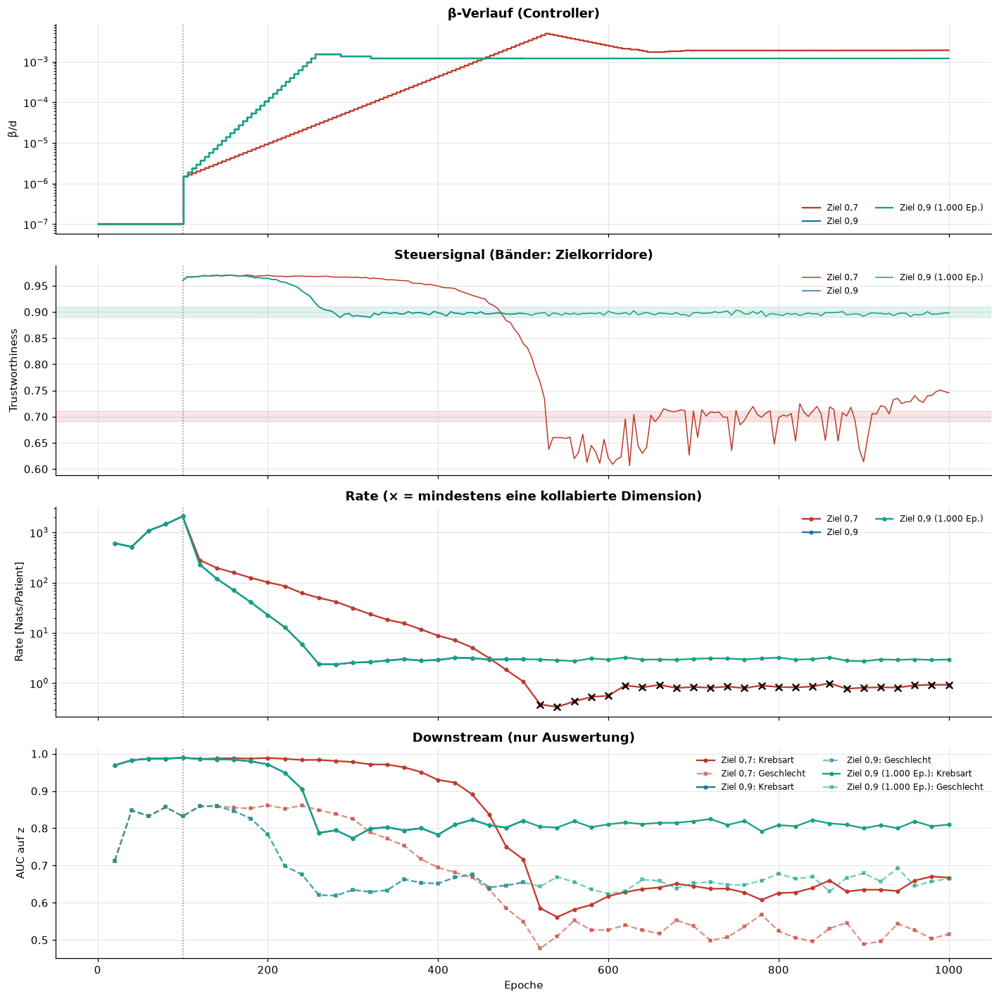

In [2]:
fig, axes = plt.subplots(4, 1, figsize=(13, 13), sharex=True)
for run in COLLAPSE_RUNS:
    controller = pd.read_csv(run_folder(run) / "controller_log.csv")
    measured = controller.dropna(subset=["metric_value"])
    group = snapshots[snapshots.run.eq(run)].sort_values("epoch")
    color = RUN_COLORS[run]
    axes[0].step(controller.epoch, controller.beta_over_d.clip(lower=1e-7), where="post", color=color, label=run)
    axes[1].plot(measured.epoch, measured.metric_value, color=color, lw=1, label=run)
    axes[2].plot(group.epoch, group.rate, "o-", ms=3, color=color, label=run)
    collapsed = group[group.collapsed_dimensions > 0]
    axes[2].scatter(collapsed.epoch, collapsed.rate, marker="x", s=40, color="black", zorder=3)
    axes[3].plot(group.epoch, group.auc_cancer, "o-", ms=3, color=color, label=f"{run}: Krebsart")
    axes[3].plot(group.epoch, group.auc_sex, "s--", ms=3, color=color, alpha=.55, label=f"{run}: Geschlecht")
for target, run in ((.7, "Ziel 0,7"), (.9, "Ziel 0,9 (1.000 Ep.)")):
    axes[1].axhspan(target - .01, target + .01, color=RUN_COLORS[run], alpha=.12)
axes[0].set(yscale="log", ylabel="β/d", title="β-Verlauf (Controller)")
axes[1].set(ylabel="Trustworthiness", title="Steuersignal (Bänder: Zielkorridore)")
axes[2].set(yscale="log", ylabel="Rate [Nats/Patient]", title="Rate (× = mindestens eine kollabierte Dimension)")
axes[3].set(ylabel="AUC auf z", xlabel="Epoche", title="Downstream (nur Auswertung)")
for ax in axes:
    ax.axvline(REFERENCE_EPOCH, color="gray", ls=":", lw=1)
    ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "overview.png", dpi=150); plt.show()

late = snapshots[snapshots.epoch >= 300].groupby("run")[["beta_over_d", "rate", "trustworthiness", "auc_cancer", "auc_sex",
                                                          "collapsed_dimensions", "zero_patients"]].agg(["mean", "min", "max"])
display(late.style.format(precision=3).set_caption("Ab Epoche 300: Mittel, Minimum, Maximum je Lauf"))

### 1.1 Regelgüte: Wie gut hält der Controller das Zielband?

Pro Lauf: erste Messung im Zielband (±0,01), Anteil der Messungen danach im Band, größte Abweichung nach dem ersten
Erreichen, Zahl der β-Änderungen danach und das End-β. Darunter für den 1.000-Epochen-Lauf das Protokoll aller
Zustandswechsel des Controllers (nur Zeilen, in denen sich Zustand oder Gewicht ändert).

In [3]:
control_rows = []
for run in COLLAPSE_RUNS:
    controller = pd.read_csv(run_folder(run) / "controller_log.csv")
    measured = controller.dropna(subset=["metric_value"])
    inside = (measured.metric_value - measured.target).abs() <= measured.tolerance + 1e-12
    first = measured[inside].epoch.min()
    after = measured[measured.epoch >= first]
    changes = controller[controller.epoch >= first].w.diff().fillna(0).ne(0).sum()
    control_rows.append(dict(run=run, sollwert=measured.target.iloc[-1], erstes_mal_im_band=first,
                             anteil_im_band_danach=inside[measured.epoch >= first].mean(),
                             max_abweichung_danach=(after.metric_value - after.target).abs().max(),
                             min_T_danach=after.metric_value.min(), beta_aenderungen_danach=int(changes),
                             beta_over_d_ende=controller.beta_over_d.iloc[-1], letzter_zustand=controller.state.iloc[-1]))
control_quality = pd.DataFrame(control_rows)
control_quality.to_csv(COLLAPSE_ROOT / "control_quality.csv", index=False)
display(control_quality.style.format(precision=3).format({"erstes_mal_im_band": "{:.0f}", "beta_over_d_ende": "{:.2e}",
        "anteil_im_band_danach": "{:.0%}"}).hide(axis="index"))

controller = pd.read_csv(run_folder("Ziel 0,9 (1.000 Ep.)") / "controller_log.csv")
changed = controller[controller.state.ne(controller.state.shift()) | controller.w.ne(controller.w.shift())]
display(changed[["epoch", "w", "beta_over_d", "metric_value", "state", "reason"]]
        .style.format({"w": "{:.4g}", "beta_over_d": "{:.3e}", "metric_value": "{:.3f}"}, na_rep="–").hide(axis="index")
        .set_caption("Ziel 0,9 (1.000 Ep.): Zustandswechsel des Controllers"))

run,sollwert,erstes_mal_im_band,anteil_im_band_danach,max_abweichung_danach,min_T_danach,beta_aenderungen_danach,beta_over_d_ende,letzter_zustand
"Ziel 0,7",0.700000,620,40%,0.093509,0.606491,45,1.92e-03,seeking
"Ziel 0,9",0.900000,260,96%,0.010671,0.889329,2,1.21e-03,hold
"Ziel 0,9 (1.000 Ep.)",0.900000,260,99%,0.010671,0.889329,2,1.21e-03,hold


epoch,w,beta_over_d,metric_value,state,reason
1,0,0.000e+00,–,warmup,–
101,0.0001,1.500e-06,–,seeking,above_target
106,0.000125,1.875e-06,–,seeking,above_target
111,0.0001563,2.344e-06,–,seeking,above_target
116,0.0001953,2.930e-06,–,seeking,above_target
121,0.0002441,3.662e-06,–,seeking,above_target
126,0.0003052,4.578e-06,–,seeking,above_target
131,0.0003815,5.722e-06,–,seeking,above_target
136,0.0004768,7.153e-06,–,seeking,above_target
141,0.000596,8.941e-06,–,seeking,above_target


## 2. Collapse-Analyse: was zuerst, was zuletzt, was danach, und bei welchem Wert

Vier Fragen an die drei Annealing-Läufe (d = 8, Seed 17):

1. **Was wird zuerst zerstört, was zuletzt?** Pro Signal die Epoche (und das β/d), ab der es 2 %, 5 % bzw. 20 % schlechter ist als am Ende des Warm-ups.
2. **Welche Dimensionen kollabieren, und was trugen sie?** KL je Dimension über die Epochen und der Anteil der μ-Varianz je Dimension, den Krebsart bzw. Geschlecht erklären (η²).
3. **Was passiert nach dem Collapse?** Erholen sich Rate, Dimensionen, Preservation und AUC, wenn der Controller β danach wieder senkt?
4. **Bei welchem Trustworthiness- bzw. MRRE-false-Wert liegt der Collapse?** Im Annealing-Lauf und, mit 24 Trajektorien, im β-Sweep.

Der Lauf mit Ziel 0,7 kollabiert, die Läufe mit Ziel 0,9 (500 und 1.000 Epochen) nicht.
Grundlage sind die Snapshots alle 20 Epochen (μ, logvar, z für Train und Validation).
Collapse wie oben: ε-δ, mindestens 99 % der Patienten einer Dimension mit KL < 0,01.
Preservation auf dem festen Controller-Subset (800 Validierungspatienten, k = 20),
AUC auf z (Logistische Regression auf Train, AUC auf Validation). Labels werden nur ausgewertet.

**Wichtig für die Interpretation: μ ist in Varix nach unten abgeschnitten.**
AUTOENCODIX setzt im Encoder `mu = torch.where(mu < 1e-7, 0, mu)` (`autoencodix/modeling/_varix_architecture.py`, Zeile 129),
zusätzlich zur bekannten Klemme `logvar ∈ [0,01; 20]`. Jede μ-Koordinate ist also ≥ 0 und wirkt wie hinter einer ReLU:
unterhalb der Schwelle ist sie exakt 0 und bekommt **keinen Gradienten** mehr. Der KL-Term zieht μ Richtung 0, also genau an
diese Kante. Deshalb werden unten zwei zusätzliche Collapse-Signale mitgeführt: der Anteil der μ-Einträge, die exakt 0 sind,
und der Anteil der Patienten, deren μ in **allen** Dimensionen 0 ist (Patienten-Collapse: diese Patienten sind in μ nicht mehr
unterscheidbar). Duplikate stören rangbasierte Maße, wenn ein Punkt nicht zuerst als er selbst erkannt wird: ZADU
streicht die erste Spalte der sortierten Nachbarliste als „selbst“. `measure_preservation` übergibt ZADU für MRRE false
und LCMC deshalb Nachbarlisten, in denen jeder Punkt an erster Stelle steht (offizielle Argumente `knn_ranking_info` /
`knn_info`, wie sklearn bei Trustworthiness); beide bleiben so messbar. Nur Cohesiveness (ZADU SNC) ist bei Duplikaten gesperrt.

### 2.1 Was wird zuerst zerstört, was zuletzt?

Referenz ist der Snapshot am Ende des Warm-ups (Epoche 100, β = 0). Für jedes Signal wird der relative Verlust
gegenüber dieser Referenz in der jeweils schlechten Richtung berechnet: Preservation und AUC fallen,
Rekonstruktionsfehler steigt, aktive Dimensionen = 8 − kollabierte. Die Zeitleiste zeigt die erste Snapshot-Epoche,
ab der 2 % (kleiner Kreis), 5 % (mittel) bzw. 20 % (groß) Verlust erreicht sind; die Signale sind nach dem 5 %-Zeitpunkt
sortiert. Schraffiert: ab hier nicht messbar (nur Cohesiveness; Duplikate bei μ = 0). Die Rate ist die Ursache und steht deshalb nicht
in der Rangliste, sondern oben im Verlaufsplot. Snapshots liegen 20 Epochen auseinander.

run,signal,epoch_2%,beta_over_d_2%,epoch_5%,beta_over_d_5%,epoch_20%,beta_over_d_20%,nicht_messbar_ab,max_verlust_%
"Ziel 0,7",Rekonstruktionsfehler,120,0.000002,200,0.000009,320,0.000090,–,142.628684
"Ziel 0,7",AUC Geschlecht,320,0.000090,320,0.000090,460,0.001303,–,42.623961
"Ziel 0,7",Cohesiveness,300,0.000062,340,0.000132,–,–,380,11.435072
"Ziel 0,7",LCMC,340,0.000132,380,0.000284,440,0.000890,–,87.400289
"Ziel 0,7",AUC Krebsart,360,0.000194,400,0.000415,480,0.001908,–,43.243454
"Ziel 0,7",MRRE false,420,0.000608,460,0.001303,520,0.004090,–,39.810034
"Ziel 0,7",Trustworthiness,440,0.000890,480,0.001908,520,0.004090,–,36.015737
"Ziel 0,7",aktive Dimensionen,520,0.004090,520,0.004090,520,0.004090,–,62.500000
"Ziel 0,9",Rekonstruktionsfehler,120,0.000003,140,0.000007,200,0.000104,–,98.124191
"Ziel 0,9",AUC Geschlecht,200,0.000104,200,0.000104,260,0.001515,–,25.600685


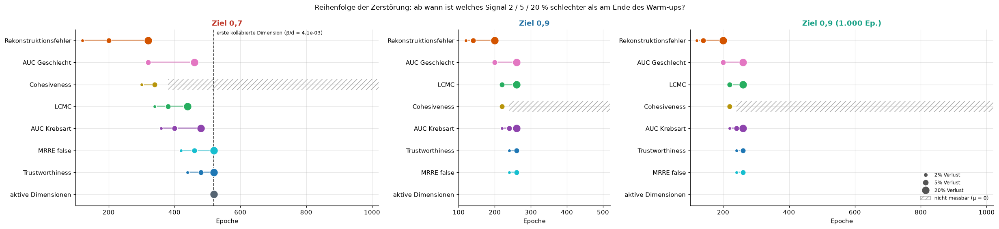

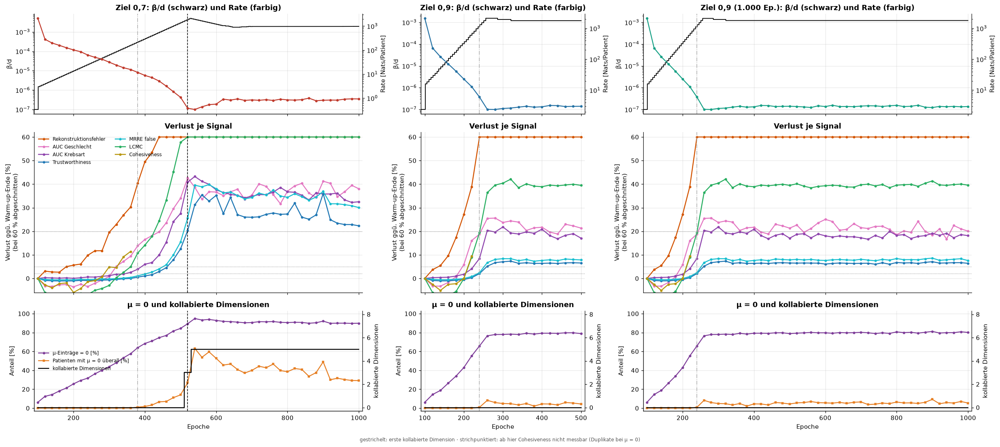

In [4]:
SIGNALS = {"recon_valid": ("Rekonstruktionsfehler", -1, "#d35400"),
           "auc_sex": ("AUC Geschlecht", +1, "#e377c2"),
           "auc_cancer": ("AUC Krebsart", +1, "#8e44ad"),
           "trustworthiness": ("Trustworthiness", +1, "#1f77b4"),
           "mrre_false": ("MRRE false", +1, "#17becf"),
           "lcmc": ("LCMC", +1, "#27ae60"),
           "cohesiveness": ("Cohesiveness", +1, "#b7950b"),
           "active_dimensions": ("aktive Dimensionen", +1, "#566573")}
THRESHOLDS = (0.02, 0.05, 0.20)


def relative_loss(group, column, direction):
    reference = group.loc[group.epoch.eq(REFERENCE_EPOCH), column].iloc[0]
    change = (group[column] - reference) / abs(reference)
    return -change if direction > 0 else change


order_rows = []
for run, group in snapshots.groupby("run"):
    group = group[group.epoch >= REFERENCE_EPOCH].sort_values("epoch").reset_index(drop=True)
    for column, (label, direction, _) in SIGNALS.items():
        loss = relative_loss(group, column, direction)
        row = dict(run=run, signal=label)
        for threshold in THRESHOLDS:
            hit = group[loss >= threshold]
            row[f"epoch_{threshold:.0%}"] = hit.epoch.iloc[0] if len(hit) else np.nan
            row[f"beta_over_d_{threshold:.0%}"] = hit.beta_over_d.iloc[0] if len(hit) else np.nan
        missing = group[group[column].isna()]
        row["nicht_messbar_ab"] = missing.epoch.iloc[0] if len(missing) else np.nan
        row["max_verlust_%"] = 100 * loss.max()
        order_rows.append(row)
destruction_order = pd.DataFrame(order_rows).sort_values(["run", "epoch_5%", "epoch_2%"], na_position="last")
destruction_order.to_csv(COLLAPSE_ROOT / "destruction_order.csv", index=False)
display(destruction_order.style.format(precision=1, na_rep="–")
        .format({c: "{:.2e}" for c in destruction_order if c.startswith("beta")}, na_rep="–")
        .format({c: "{:.0f}" for c in destruction_order if c.startswith("epoch") or c == "nicht_messbar_ab"}, na_rep="–")
        .hide(axis="index"))

# Zeitleiste: wann erreicht welches Signal 2 / 5 / 20 % Verlust?
fig, axes = plt.subplots(1, NCOLS, figsize=(7.5 * NCOLS, 5.2), gridspec_kw=dict(width_ratios=WIDTHS))
for ax, run in zip(axes, COLLAPSE_RUNS):
    table = destruction_order[destruction_order.run.eq(run)].reset_index(drop=True)
    epochs = snapshots[snapshots.run.eq(run)].epoch
    for y, row in table.iterrows():
        color = [c for _, (label, _, c) in SIGNALS.items() if label == row.signal][0]
        hits = [row[f"epoch_{t:.0%}"] for t in THRESHOLDS]
        valid = [h for h in hits if np.isfinite(h)]
        if valid:
            ax.plot([min(valid), max(valid)], [y, y], color=color, lw=2.5, alpha=.5)
        for hit, size in zip(hits, (30, 80, 170)):
            if np.isfinite(hit):
                ax.scatter(hit, y, s=size, color=color, edgecolor="white", zorder=3)
        if np.isfinite(row.nicht_messbar_ab):
            ax.barh(y, epochs.max() + 20 - row.nicht_messbar_ab, left=row.nicht_messbar_ab, height=.5,
                    color="none", edgecolor="#aaaaaa", hatch="///", lw=0)
    if run in first_collapse:
        ax.axvline(first_collapse[run], color="black", ls="--", lw=1.2)
        beta = snapshots[(snapshots.run == run) & (snapshots.epoch == first_collapse[run])].beta_over_d.iloc[0]
        ax.text(first_collapse[run] + 8, -.45, f"erste kollabierte Dimension (β/d = {beta:.1e})", fontsize=8, va="top")
    ax.set(yticks=range(len(table)), yticklabels=table.signal, xlim=(REFERENCE_EPOCH, epochs.max() + 20),
           ylim=(len(table) - .5, -.5), xlabel="Epoche", title=run)
    ax.title.set_color(RUN_COLORS[run])
legend = [Line2D([], [], ls="", marker="o", ms=s, color="#555555", label=f"{t:.0%} Verlust") for t, s in zip(THRESHOLDS, (5, 8, 11))]
legend.append(plt.Rectangle((0, 0), 1, 1, facecolor="none", edgecolor="#aaaaaa", hatch="///", label="nicht messbar (μ = 0)"))
axes[-1].legend(handles=legend, loc="lower right", fontsize=8)
fig.suptitle("Reihenfolge der Zerstörung: ab wann ist welches Signal 2 / 5 / 20 % schlechter als am Ende des Warm-ups?", fontsize=11)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "destruction_timeline.png", dpi=160); plt.show()

# Verläufe: oben Ursache (β/d, Rate), Mitte Verlust je Signal, unten Collapse-Signale
fig, axes = plt.subplots(3, NCOLS, figsize=(7.5 * NCOLS, 10), sharex="col", gridspec_kw=dict(width_ratios=WIDTHS, height_ratios=[1, 1.6, 1]))
for column_index, run in enumerate(COLLAPSE_RUNS):
    group = snapshots[snapshots.run.eq(run) & (snapshots.epoch >= REFERENCE_EPOCH)].sort_values("epoch").reset_index(drop=True)
    controller = pd.read_csv(run_folder(run) / "controller_log.csv")
    top, middle, bottom = axes[:, column_index]
    top.step(controller.epoch, controller.beta_over_d.clip(lower=1e-7), where="post", color="black", lw=1.2, label="β/d")
    top.set(yscale="log", ylabel="β/d")
    twin = top.twinx()
    twin.plot(group.epoch, group.rate, "o-", ms=3, color=RUN_COLORS[run], label="Rate")
    twin.set(yscale="log", ylabel="Rate [Nats/Patient]")
    twin.spines["right"].set_visible(True); twin.grid(False)
    top.set_title(f"{run}: β/d (schwarz) und Rate (farbig)")
    top.set_xlim(REFERENCE_EPOCH - 10, group.epoch.max() + 10)
    for column, (label, direction, color) in SIGNALS.items():
        if column == "active_dimensions":
            continue
        loss = 100 * relative_loss(group, column, direction)
        middle.plot(group.epoch, loss.clip(upper=60), "o-", ms=3, lw=1.6, color=color, label=label)
    for threshold in THRESHOLDS:
        middle.axhline(100 * threshold, color="gray", ls=":", lw=.8)
    middle.set(ylabel="Verlust ggü. Warm-up-Ende [%]\n(bei 60 % abgeschnitten)", ylim=(-6, 62),
               title="Verlust je Signal")
    bottom.plot(group.epoch, 100 * group.zero_entries, "o-", ms=3, color="#7d3c98", label="μ-Einträge = 0 [%]")
    bottom.plot(group.epoch, 100 * group.zero_patients, "s-", ms=3, color="#e67e22", label="Patienten mit μ = 0 überall [%]")
    bottom.set(ylabel="Anteil [%]", xlabel="Epoche", ylim=(-3, 103), title="μ = 0 und kollabierte Dimensionen")
    dims = bottom.twinx()
    dims.step(group.epoch, group.collapsed_dimensions, where="mid", color="black", lw=1.5, label="kollabierte Dimensionen")
    dims.set(ylim=(-.3, 8.3), ylabel="kollabierte Dimensionen"); dims.spines["right"].set_visible(True); dims.grid(False)
    for ax in (top, middle, bottom):
        if run in first_collapse:
            ax.axvline(first_collapse[run], color="black", ls="--", lw=1)
        if run in zadu_gone:
            ax.axvline(zadu_gone[run], color="#aaaaaa", ls="-.", lw=1)
    if column_index == 0:
        middle.legend(fontsize=8, ncol=2, loc="upper left")
        handles = bottom.get_legend_handles_labels()[0] + dims.get_legend_handles_labels()[0]
        bottom.legend(handles=handles, fontsize=8, loc="center left")
fig.text(.5, .005, "gestrichelt: erste kollabierte Dimension · strichpunktiert: ab hier Cohesiveness nicht messbar (Duplikate bei μ = 0)",
         ha="center", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, .015, 1, 1)); fig.savefig(COLLAPSE_ROOT / "destruction_curves.png", dpi=160); plt.show()

### 2.2 Welche Dimensionen kollabieren, und was trugen sie?

Oben je Lauf die mittlere KL je latenter Dimension über die Epochen (log-Skala; dunkel = keine Information mehr)
und der Anteil der Patienten, deren μ in dieser Dimension exakt 0 ist. Unten für jede Dimension, wie viel ihrer
μ-Varianz Krebsart bzw. Geschlecht erklären (η², 0 bis 1), gemessen am letzten Snapshot vor dem ersten Collapse.
Rot umrandet: Dimension kollabiert später. So sieht man, ob zuerst Dimensionen ohne Label-Bezug verschwinden
oder ob gezielt Krebs- oder Geschlechtsinformation geopfert wird.

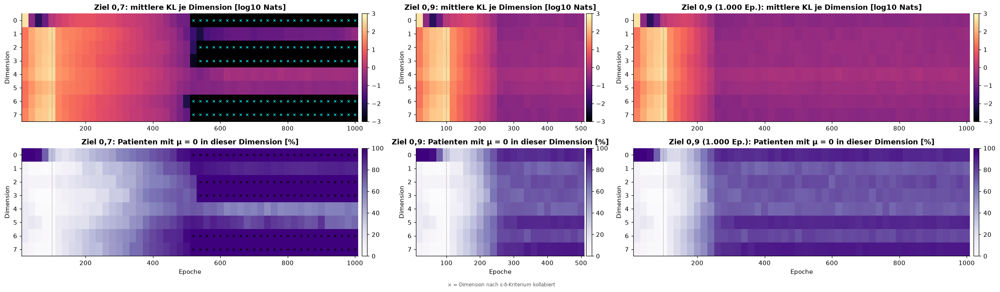

run,dim,collapse_epoch,reaktiviert,kl_warmup,kl_vorher,mu_0_vorher,eta2_krebs_vorher,eta2_sex_vorher,snapshot_vorher
"Ziel 0,7",6,520,False,275.686124,0.006178,0.977023,0.293571,0.013346,500
"Ziel 0,7",7,520,False,343.019248,0.063646,0.944056,0.523061,0.023083,500
"Ziel 0,7",0,520,False,1.047461,0.094775,0.954046,0.905935,0.417056,500
"Ziel 0,7",3,540,False,302.599096,0.146657,0.705295,0.786247,0.006089,500
"Ziel 0,7",2,540,False,279.319378,0.157491,0.746254,0.312981,0.012169,500
"Ziel 0,7",1,–,False,330.545753,0.075096,0.804196,0.407615,0.005629,500
"Ziel 0,7",5,–,False,172.556380,0.239363,0.903097,0.786889,0.001759,500
"Ziel 0,7",4,–,False,388.872038,0.298109,0.717283,0.648004,0.008357,500
"Ziel 0,9",0,–,False,1.047461,0.270132,0.862138,0.831683,0.428773,500
"Ziel 0,9",7,–,False,343.019248,0.274015,0.910090,0.769703,0.050151,500


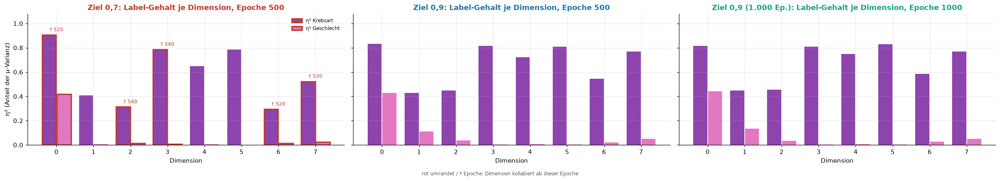

In [5]:
fig, axes = plt.subplots(2, NCOLS, figsize=(7.5 * NCOLS, 6.5), gridspec_kw=dict(width_ratios=WIDTHS))
for column_index, run in enumerate(COLLAPSE_RUNS):
    table = dimensions[dimensions.run.eq(run)]
    for row_index, (value, title, cmap, limits, transform) in enumerate((
            ("kl_mean", "mittlere KL je Dimension [log10 Nats]", "magma", (-3, 3), lambda v: np.log10(v.clip(lower=1e-3))),
            ("zero_fraction", "Patienten mit μ = 0 in dieser Dimension [%]", "Purples", (0, 100), lambda v: 100 * v))):
        ax = axes[row_index, column_index]
        grid = table.pivot(index="dim", columns="epoch", values=value)
        image = ax.imshow(transform(grid), aspect="auto", cmap=cmap, vmin=limits[0], vmax=limits[1],
                          extent=(grid.columns.min() - 10, grid.columns.max() + 10, 7.5, -.5), interpolation="nearest")
        collapsed = table.pivot(index="dim", columns="epoch", values="collapsed")
        ys, xs = np.nonzero(collapsed.to_numpy())
        ax.scatter(collapsed.columns.to_numpy()[xs], ys, marker="x", s=12, color="cyan" if row_index == 0 else "black", lw=.8)
        ax.axvline(REFERENCE_EPOCH, color="gray", ls=":", lw=1)
        ax.set(yticks=range(8), ylabel="Dimension", title=f"{run}: {title}", xlabel="Epoche" if row_index else None)
        ax.grid(False)
        fig.colorbar(image, ax=ax, pad=.01, fraction=.04)
fig.text(.5, .005, "× = Dimension nach ε-δ-Kriterium kollabiert", ha="center", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, .02, 1, 1)); fig.savefig(COLLAPSE_ROOT / "kl_per_dimension.png", dpi=160); plt.show()

summary_rows = []
for run in COLLAPSE_RUNS:
    table = dimensions[dimensions.run.eq(run)]
    before = first_collapse.get(run, table.epoch.max() + 20) - 20
    at_before = table[table.epoch.eq(before)].set_index("dim")
    at_reference = table[table.epoch.eq(REFERENCE_EPOCH)].set_index("dim")
    for dim in range(8):
        collapsed_epochs = table[table.dim.eq(dim) & table.collapsed].epoch
        later = table[table.dim.eq(dim) & (table.epoch > collapsed_epochs.min())] if len(collapsed_epochs) else table.iloc[:0]
        summary_rows.append(dict(
            run=run, dim=dim, collapse_epoch=collapsed_epochs.min() if len(collapsed_epochs) else np.nan,
            reaktiviert=bool(len(later) and not later.collapsed.all()),
            kl_warmup=at_reference.loc[dim, "kl_mean"], kl_vorher=at_before.loc[dim, "kl_mean"],
            mu_0_vorher=at_before.loc[dim, "zero_fraction"],
            eta2_krebs_vorher=at_before.loc[dim, "eta2_cancer"], eta2_sex_vorher=at_before.loc[dim, "eta2_sex"],
            snapshot_vorher=before))
dimension_summary = pd.DataFrame(summary_rows).sort_values(["run", "collapse_epoch", "kl_vorher"], na_position="last")
dimension_summary.to_csv(COLLAPSE_ROOT / "dimension_summary.csv", index=False)
display(dimension_summary.style.format(precision=3, na_rep="–")
        .format({"collapse_epoch": "{:.0f}", "snapshot_vorher": "{:.0f}"}, na_rep="–").hide(axis="index"))

fig, axes = plt.subplots(1, NCOLS, figsize=(7.5 * NCOLS, 4), sharey=True)
for ax, run in zip(axes, COLLAPSE_RUNS):
    table = dimension_summary[dimension_summary.run.eq(run)].sort_values("dim")
    edge = ["#c0392b" if np.isfinite(e) else "none" for e in table.collapse_epoch]
    ax.bar(table.dim - .2, table.eta2_krebs_vorher, .38, color="#8e44ad", edgecolor=edge, lw=2.2, label="η² Krebsart")
    ax.bar(table.dim + .2, table.eta2_sex_vorher, .38, color="#e377c2", edgecolor=edge, lw=2.2, label="η² Geschlecht")
    for _, row in table[np.isfinite(table.collapse_epoch)].iterrows():
        ax.text(row.dim, max(row.eta2_krebs_vorher, row.eta2_sex_vorher) + .03, f"† {row.collapse_epoch:.0f}",
                ha="center", fontsize=8, color="#c0392b")
    ax.set(title=f"{run}: Label-Gehalt je Dimension, Epoche {table.snapshot_vorher.iloc[0]:.0f}",
           xlabel="Dimension", xticks=range(8), ylim=(0, 1.08))
    ax.title.set_color(RUN_COLORS[run])
axes[0].set_ylabel("η² (Anteil der μ-Varianz)")
axes[0].legend(fontsize=8, loc="upper right")
fig.text(.5, .005, "rot umrandet / † Epoche: Dimension kollabiert ab dieser Epoche", ha="center", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, .03, 1, 1)); fig.savefig(COLLAPSE_ROOT / "label_content_per_dimension.png", dpi=160); plt.show()

### 2.3 Was passiert nach dem Collapse?

Nach dem ersten Collapse senkt der Controller β wieder, weil Trustworthiness unter das Zielband fällt.
Die Tabelle vergleicht fünf Zeitpunkte des kollabierenden Laufs: Ende Warm-up, letzter Snapshot vor dem Collapse,
erster Snapshot mit Collapse, schlechtester Trustworthiness-Wert danach und Laufende. Dazu der Patienten-Collapse
je Krebsart: Welche Krebsarten landen bei μ = 0, also beim Prior-Mittelwert?

run,moment,epoch,beta_over_d,rate,collapsed_dimensions,zero_entries,zero_patients,trustworthiness,auc_cancer,auc_sex,recon_valid
"Ziel 0,7",Ende Warm-up,100,0.00e+00,2093.65,0,6%,0%,0.959779,0.989250,0.832090,3.88e-04
"Ziel 0,7",letzter vor Collapse,500,2.79e-03,1.08,0,84%,14%,0.839719,0.716692,0.549049,8.40e-04
"Ziel 0,7",erster mit Collapse,520,4.09e-03,0.38,3,89%,27%,0.765035,0.585290,0.477421,9.25e-04
"Ziel 0,7",Tiefpunkt danach (T),900,1.90e-03,0.81,5,92%,49%,0.614108,0.634934,0.488874,8.87e-04
"Ziel 0,7",Laufende,1000,1.92e-03,0.93,5,90%,29%,0.745604,0.667499,0.515682,8.70e-04


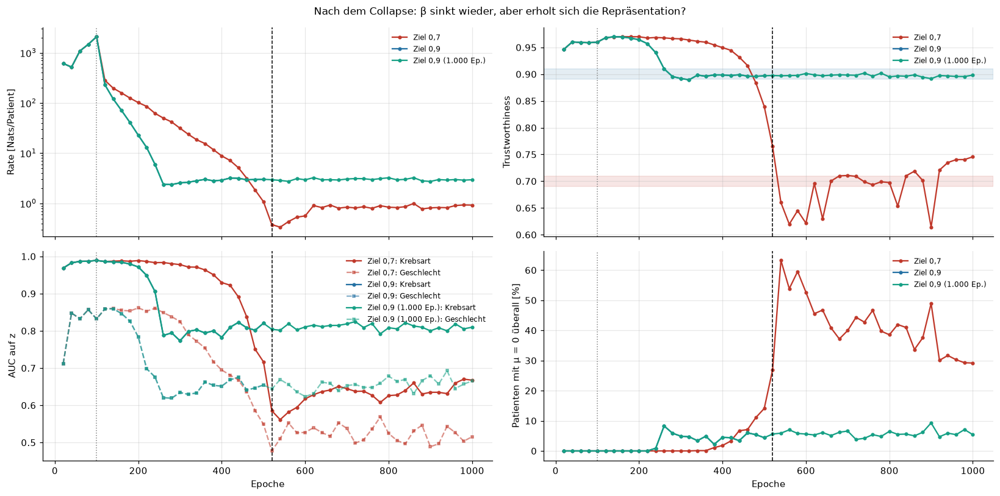

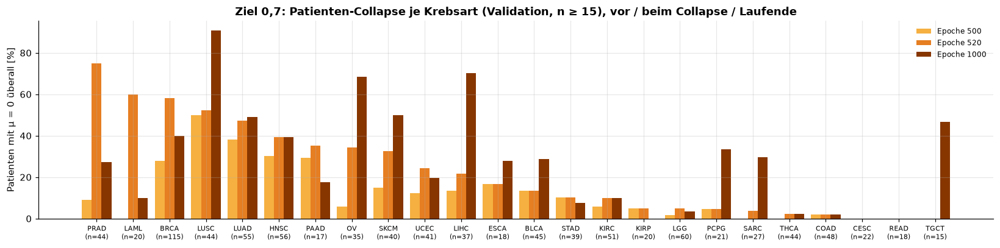

In [6]:
COLUMNS = ["epoch", "beta_over_d", "rate", "collapsed_dimensions", "zero_entries", "zero_patients", "trustworthiness",
           "auc_cancer", "auc_sex", "recon_valid"]
after_rows = []
for run in COLLAPSE_RUNS:
    if run not in first_collapse:
        continue
    group = snapshots[snapshots.run.eq(run)].sort_values("epoch").set_index("epoch", drop=False)
    onset = first_collapse[run]
    after = group[group.epoch >= onset]
    moments = {"Ende Warm-up": REFERENCE_EPOCH, "letzter vor Collapse": onset - 20, "erster mit Collapse": onset,
               "Tiefpunkt danach (T)": after.trustworthiness.idxmin(), "Laufende": group.epoch.max()}
    for moment, epoch in moments.items():
        after_rows.append(dict(run=run, moment=moment, **group.loc[epoch, COLUMNS].to_dict()))
after_collapse = pd.DataFrame(after_rows)
after_collapse.to_csv(COLLAPSE_ROOT / "after_collapse.csv", index=False)
display(after_collapse.style.format(precision=3).format({"epoch": "{:.0f}", "collapsed_dimensions": "{:.0f}",
        "beta_over_d": "{:.2e}", "rate": "{:.2f}", "recon_valid": "{:.2e}",
        "zero_entries": "{:.0%}", "zero_patients": "{:.0%}"}).hide(axis="index"))

fig, axes = plt.subplots(2, 2, figsize=(15, 7.5), sharex=True)
panels = [("rate", "Rate [Nats/Patient]", "log", None), ("trustworthiness", "Trustworthiness", None, None),
          ("auc_cancer", "AUC auf z", None, "auc_sex"), ("zero_patients", "Patienten mit μ = 0 überall [%]", None, None)]
for ax, (column, ylabel, scale, second) in zip(axes.flat, panels):
    for run, group in snapshots.groupby("run"):
        group = group.sort_values("epoch")
        values = 100 * group[column] if column == "zero_patients" else group[column]
        ax.plot(group.epoch, values, "o-", ms=3, color=RUN_COLORS[run], label=run if not second else f"{run}: Krebsart")
        if second:
            ax.plot(group.epoch, group[second], "s--", ms=3, color=RUN_COLORS[run], alpha=.55, label=f"{run}: Geschlecht")
    if column == "trustworthiness":
        for target, run in ((.7, "Ziel 0,7"), (.9, "Ziel 0,9")):
            ax.axhspan(target - .01, target + .01, color=RUN_COLORS[run], alpha=.12)
    for run, epoch in first_collapse.items():
        ax.axvline(epoch, color="black", ls="--", lw=1)
    ax.axvline(REFERENCE_EPOCH, color="gray", ls=":", lw=1)
    ax.set(ylabel=ylabel, yscale=scale or "linear")
    ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Epoche")
fig.suptitle("Nach dem Collapse: β sinkt wieder, aber erholt sich die Repräsentation?", fontsize=11)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "after_collapse.png", dpi=160); plt.show()

# Patienten-Collapse je Krebsart (Validation) im kollabierenden Lauf
run = "Ziel 0,7"
folder = run_folder(run)
labels = pd.read_parquet(folder / "epoch_snapshots" / "labels_valid.parquet")
labels.index = labels.index.astype(str)
by_type = {}
for epoch in (first_collapse[run] - 20, first_collapse[run], snapshots[snapshots.run.eq(run)].epoch.max()):
    with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_valid.npz") as saved:
        ids, mu = saved["sample_ids"].astype(str), saved["mu"]
    by_type[f"Epoche {epoch}"] = pd.Series((mu == 0).all(1), index=ids).groupby(labels.loc[ids].CANCER_TYPE_ACRONYM.to_numpy()).mean()
by_type = pd.DataFrame(by_type)
by_type["n"] = labels.CANCER_TYPE_ACRONYM.value_counts()
by_type = by_type[by_type.n >= 15].sort_values(by_type.columns[1], ascending=False)
by_type.to_csv(COLLAPSE_ROOT / "patient_collapse_by_cancer.csv")
fig, ax = plt.subplots(figsize=(15, 3.8))
positions = np.arange(len(by_type))
for offset, (column, color) in zip((-.27, 0, .27), zip(by_type.columns[:3], ("#f5b041", "#e67e22", "#873600"))):
    ax.bar(positions + offset, 100 * by_type[column], .27, color=color, label=column)
ax.set(xticks=positions, ylabel="Patienten mit μ = 0 überall [%]",
       title=f"{run}: Patienten-Collapse je Krebsart (Validation, n ≥ 15), vor / beim Collapse / Laufende")
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(by_type.index, by_type.n)], fontsize=7)
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "patient_collapse_by_cancer.png", dpi=160); plt.show()

### 2.4 Bei welchem Trustworthiness- bzw. MRRE-false-Wert liegt der Collapse?

**Annealing-Lauf:** Der Controller misst Trustworthiness alle 5 Epochen, Collapse ist nur an den Snapshots
(alle 20 Epochen) bestimmbar. Der Collapse liegt also zwischen zwei Snapshots; angegeben werden die Werte am letzten
Snapshot ohne und am ersten mit Collapse sowie die Controller-Messungen dazwischen.

**β-Sweep (24 Trajektorien, 240 Läufe):** Pro Trajektorie (d, Seed) der Wert beim größten β ohne und beim kleinsten β
mit kollabierter Dimension, gemessen auf dem Test-μ (alle Testpatienten, k = 20). Im Plot ist jede Trajektorie eine
Linie von „ohne“ nach „mit Collapse“. Zusätzlich eine logistische Regression P(mindestens eine Dimension kollabiert | Metrik)
über alle Läufe: der Metrikwert bei 50 % und bei 5 % Collapse-Wahrscheinlichkeit. Sweep und Annealing nutzen dieselbe
Metrikdefinition, aber andere Patienten und Stichprobengrößen.

**Achtung, anderer Datensatz:** Der β-Sweep (29.09.) lief auf `OntixTutorialData` (3.529 Patienten, 90 Epochen ohne
Annealing), die Annealing-Läufe auf `TCGAPanCancerAutoencodix` (Zenodo 15518831, 10.013 Patienten). Unterschiede zwischen
Sweep- und Annealing-Werten können deshalb auch am Datensatz liegen, nicht nur am Trainingsweg.

quelle,metric,ohne_collapse,mit_collapse,controller_T_dazwischen,ohne_q10_q90,mit_q10_q90,logit_50,logit_5
"Annealing Ziel 0,7",trustworthiness,0.840,0.765,"Ep. 505: 0.832, Ep. 510: 0.813, Ep. 515: 0.786, Ep. 520: 0.765",,,,
"Annealing Ziel 0,7",mrre_false,0.821,0.722,,,,,
"Annealing Ziel 0,7",lcmc,0.233,0.152,,,,,
Sweep (24 Trajektorien),trustworthiness,0.934,0.868,,0.813 – 0.955,0.544 – 0.956,0.803,0.992
Sweep (24 Trajektorien),mrre_false,0.931,0.853,,0.804 – 0.953,0.488 – 0.954,0.799,0.989
Sweep (24 Trajektorien),lcmc,0.371,0.240,,0.153 – 0.442,0.040 – 0.445,0.211,0.447


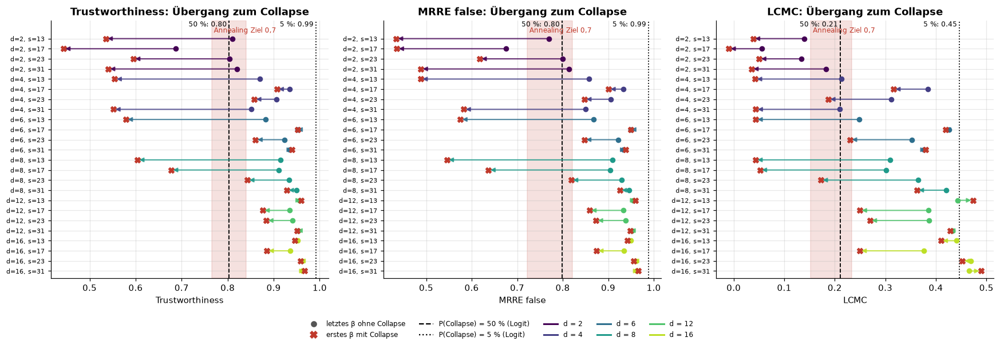

In [7]:
rows = []
for run in COLLAPSE_RUNS:
    if run not in first_collapse:
        continue
    onset = first_collapse[run]
    group = snapshots[snapshots.run.eq(run)].set_index("epoch")
    controller = pd.read_csv(run_folder(run) / "controller_log.csv")
    between = controller[(controller.epoch > onset - 20) & (controller.epoch <= onset)].dropna(subset=["metric_value"])
    for metric in ("trustworthiness", "mrre_false", "lcmc"):
        rows.append(dict(quelle=f"Annealing {run}", metric=metric, ohne_collapse=group.loc[onset - 20, metric],
                         mit_collapse=group.loc[onset, metric],
                         controller_T_dazwischen=", ".join(f"Ep. {e}: {v:.3f}" for e, v in zip(between.epoch, between.metric_value))
                         if metric == "trustworthiness" else ""))

SWEEP = PROJECT_ROOT / "beta_vae_experiments/new_results_2026-09-29/biology_breakpoints_2026_09_29/experiment_metrics.csv"
sweep = pd.read_csv(SWEEP)
COLLAPSED = "posterior_collapsed_dimensions_count_eps_0p01_delta_0p01"
SWEEP_METRICS = {"trustworthiness": ("geometry_mu_trustworthiness_zadu_k20", "Trustworthiness"),
                 "mrre_false": ("geometry_mu_mrre_false_zadu_k20", "MRRE false"),
                 "lcmc": ("geometry_mu_lcmc_zadu_k20", "LCMC")}
transitions = []
for (latent_dim, seed), group in sweep.sort_values("beta").groupby(["latent_dim", "seed"]):
    collapsed = group[group[COLLAPSED] > 0]
    if collapsed.empty:
        continue
    onset = collapsed.iloc[0]
    clean = group[(group.beta < onset.beta) & group[COLLAPSED].eq(0)]
    if clean.empty:
        continue
    last_clean = clean.iloc[-1]
    for metric, (column, _) in SWEEP_METRICS.items():
        transitions.append(dict(latent_dim=latent_dim, seed=seed, metric=metric, ohne_collapse=last_clean[column],
                                mit_collapse=onset[column], dims_beim_collapse=onset[COLLAPSED]))
transitions = pd.DataFrame(transitions)
transitions.to_csv(COLLAPSE_ROOT / "sweep_collapse_transitions.csv", index=False)

for metric, (column, _) in SWEEP_METRICS.items():
    part = transitions[transitions.metric.eq(metric)]
    data = sweep[[column, COLLAPSED]].dropna()
    model = LogisticRegression(C=1e6, max_iter=1000).fit(data[[column]], data[COLLAPSED] > 0)
    slope, intercept = model.coef_[0, 0], model.intercept_[0]
    rows.append(dict(quelle=f"Sweep ({len(part)} Trajektorien)", metric=metric,
                     ohne_collapse=part.ohne_collapse.median(), mit_collapse=part.mit_collapse.median(),
                     ohne_q10_q90=f"{part.ohne_collapse.quantile(.1):.3f} – {part.ohne_collapse.quantile(.9):.3f}",
                     mit_q10_q90=f"{part.mit_collapse.quantile(.1):.3f} – {part.mit_collapse.quantile(.9):.3f}",
                     logit_50=-intercept / slope, logit_5=(np.log(.05 / .95) - intercept) / slope))
collapse_values = pd.DataFrame(rows)
collapse_values.to_csv(COLLAPSE_ROOT / "collapse_values.csv", index=False)
display(collapse_values.style.format(precision=3, na_rep="").hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
dim_colors = dict(zip(sorted(sweep.latent_dim.unique()), plt.cm.viridis(np.linspace(0, .9, sweep.latent_dim.nunique()))))
for ax, (metric, (column, label)) in zip(axes, SWEEP_METRICS.items()):
    part = transitions[transitions.metric.eq(metric)].sort_values(["latent_dim", "seed"]).reset_index(drop=True)
    for y, row in part.iterrows():
        color = dim_colors[row.latent_dim]
        ax.annotate("", xy=(row.mit_collapse, y), xytext=(row.ohne_collapse, y),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.4, alpha=.8))
        ax.scatter(row.ohne_collapse, y, s=28, color=color, zorder=3)
        ax.scatter(row.mit_collapse, y, s=40, marker="X", color="#c0392b", zorder=3)
    value = collapse_values[collapse_values.metric.eq(metric) & collapse_values.quelle.str.startswith("Sweep")].iloc[0]
    ax.axvline(value.logit_50, color="black", ls="--", lw=1.2)
    ax.axvline(value.logit_5, color="black", ls=":", lw=1.2)
    ax.text(value.logit_50, -1.2, f"50 %: {value.logit_50:.2f} ", ha="right", fontsize=8)
    ax.text(value.logit_5, -1.2, f"5 %: {value.logit_5:.2f} ", ha="right", fontsize=8)
    for run in first_collapse.index:
        annealing = collapse_values[collapse_values.metric.eq(metric) & collapse_values.quelle.eq(f"Annealing {run}")].iloc[0]
        if np.isfinite(annealing.ohne_collapse):
            ax.axvspan(annealing.mit_collapse, annealing.ohne_collapse, color=RUN_COLORS[run], alpha=.15)
            ax.text(annealing.mit_collapse, -.6, f" Annealing {run}", color=RUN_COLORS[run], fontsize=8, ha="left")
    ax.set(yticks=range(len(part)), yticklabels=[f"d={d}, s={s}" for d, s in zip(part.latent_dim, part.seed)],
           ylim=(len(part) - .3, -1.8), xlabel=label, title=f"{label}: Übergang zum Collapse")
    ax.tick_params(axis="y", labelsize=7)
legend = [Line2D([], [], ls="", marker="o", color="#555555", label="letztes β ohne Collapse"),
          Line2D([], [], ls="", marker="X", color="#c0392b", ms=8, label="erstes β mit Collapse"),
          Line2D([], [], ls="--", color="black", label="P(Collapse) = 50 % (Logit)"),
          Line2D([], [], ls=":", color="black", label="P(Collapse) = 5 % (Logit)")]
legend += [Line2D([], [], color=c, lw=2, label=f"d = {d}") for d, c in dim_colors.items()]
fig.legend(handles=legend, loc="lower center", ncol=5, fontsize=8)
fig.tight_layout(rect=(0, .08, 1, 1)); fig.savefig(COLLAPSE_ROOT / "collapse_threshold.png", dpi=160); plt.show()

### 2.4b Vergleich mit Rate und Distortion

Dieselbe Frage für die Rate-Distortion-Größen: Rate (Gesamt-KL), Rate pro Dimension und Distortion (Rekonstruktions-MSE, Test).
Oben die Mediane beim letzten β ohne und beim ersten β mit Collapse je d, unten wie gut jedes Signal kollabierte von nicht
kollabierten Sweep-Läufen trennt (ROC-AUC, 1 = perfekt; gesamt und innerhalb eines d). Das ist eine Collapse-Diagnose,
keine Downstream-AUC.

,gesamt,d=2,d=4,d=6,d=8,d=12,d=16
signal,,,,,,,
Trustworthiness,0.894,1.000,0.980,0.940,0.994,0.936,0.898
MRRE false,0.895,1.000,0.990,0.940,0.994,0.939,0.900
Rate,0.937,1.000,0.977,0.943,0.981,0.933,0.898
Rate/d,0.957,1.000,0.977,0.943,0.981,0.933,0.898
Distortion (MSE),0.915,1.000,0.987,0.943,0.984,0.923,0.898


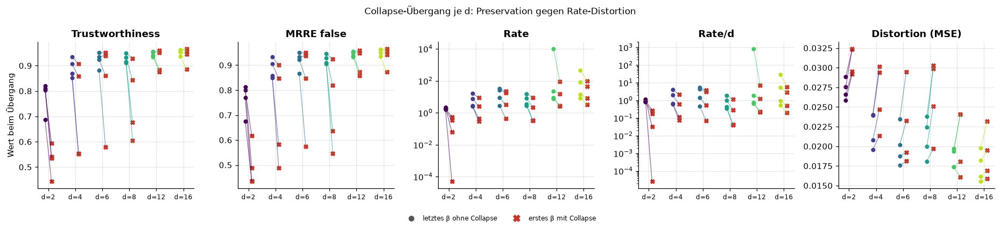

In [8]:
from sklearn.metrics import roc_auc_score

sweep["rate"] = sweep.posterior_conditional_kl_total_mean
sweep["rate_per_dim"] = sweep.rate / sweep.latent_dim
RD_SIGNALS = {"Trustworthiness": ("geometry_mu_trustworthiness_zadu_k20", +1), "MRRE false": ("geometry_mu_mrre_false_zadu_k20", +1),
              "Rate": ("rate", +1), "Rate/d": ("rate_per_dim", +1), "Distortion (MSE)": ("recon_test_mse", -1)}
rows = []
for (latent_dim, seed), group in sweep.sort_values("beta").groupby(["latent_dim", "seed"]):
    collapsed = group[group[COLLAPSED] > 0]
    if collapsed.empty:
        continue
    onset = collapsed.iloc[0]
    clean = group[(group.beta < onset.beta) & group[COLLAPSED].eq(0)]
    if clean.empty:
        continue
    for label, (column, _) in RD_SIGNALS.items():
        rows.append(dict(d=latent_dim, seed=seed, signal=label, ohne=clean.iloc[-1][column], mit=onset[column]))
rd_transitions = pd.DataFrame(rows)
rd_table = rd_transitions.groupby(["signal", "d"])[["ohne", "mit"]].median().unstack("signal").swaplevel(axis=1)
rd_table = rd_table[[(s, c) for s in RD_SIGNALS for c in ("ohne", "mit")]]
rd_table.to_csv(COLLAPSE_ROOT / "rate_distortion_collapse_values.csv")
display(rd_table.style.format(precision=3).set_caption("Median je d: letztes β ohne / erstes β mit Collapse"))

separation = []
for label, (column, direction) in RD_SIGNALS.items():
    row = dict(signal=label, gesamt=roc_auc_score(sweep[COLLAPSED] > 0, -direction * sweep[column]))
    for latent_dim, group in sweep.groupby("latent_dim"):
        row[f"d={latent_dim}"] = roc_auc_score(group[COLLAPSED] > 0, -direction * group[column])
    separation.append(row)
separation = pd.DataFrame(separation).set_index("signal")
separation.to_csv(COLLAPSE_ROOT / "collapse_separation_auc.csv")
display(separation.style.format(precision=3).background_gradient(cmap="Greens", vmin=.85, vmax=1)
        .set_caption("Trennung kollabiert / nicht kollabiert (ROC-AUC)"))

fig, axes = plt.subplots(1, len(RD_SIGNALS), figsize=(17, 3.8))
for ax, (label, (column, _)) in zip(axes, RD_SIGNALS.items()):
    part = rd_transitions[rd_transitions.signal.eq(label)]
    for latent_dim, group in part.groupby("d"):
        x = np.full(len(group), list(dim_colors).index(latent_dim))
        ax.scatter(x - .12, group.ohne, s=18, color=dim_colors[latent_dim])
        ax.scatter(x + .12, group.mit, s=24, marker="X", color="#c0392b")
        for xi, a, b in zip(x, group.ohne, group.mit):
            ax.plot([xi - .12, xi + .12], [a, b], color=dim_colors[latent_dim], lw=.8, alpha=.6)
    ax.set(xticks=range(len(dim_colors)), xticklabels=[f"d={d}" for d in dim_colors], title=label,
           yscale="log" if label.startswith("Rate") else "linear")
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("Wert beim Übergang")
fig.legend(handles=legend[:2], loc="lower center", ncol=2, fontsize=8)
fig.suptitle("Collapse-Übergang je d: Preservation gegen Rate-Distortion", fontsize=11)
fig.tight_layout(rect=(0, .07, 1, 1)); fig.savefig(COLLAPSE_ROOT / "collapse_rate_distortion.png", dpi=160); plt.show()

### 2.5 Rate gegen Trustworthiness, mit Collapse nach zwei Kriterien

Jeder Punkt ist ein Snapshot (alle 20 Epochen), verbunden in zeitlicher Reihenfolge; die Farbe zeigt, wie viele der
8 Dimensionen kollabiert bzw. inaktiv sind. Im Hintergrund (Quadrate): die d = 8-Läufe des β-Sweeps (Test-μ, alle Testpatienten); vollständig kollabierte
Sweep-Läufe mit Rate < 0,1 liegen außerhalb des gezeigten Bereichs.
Die Annealing-Trustworthiness stammt vom Validierungs-Subset (800 Patienten); beide sind vergleichbar, nicht identisch.
**Achtung, anderer Datensatz:** Der β-Sweep (29.09.) lief auf `OntixTutorialData` (3.529 Patienten, 90 Epochen ohne
Annealing), die Annealing-Läufe auf `TCGAPanCancerAutoencodix` (Zenodo 15518831, 10.013 Patienten). Unterschiede zwischen
Sweep- und Annealing-Werten können deshalb auch am Datensatz liegen, nicht nur am Trainingsweg.

Zwei gängige Definitionen, wann eine latente Dimension „weg“ ist:

- **ε-δ-Collapse (links, unsere Definition):** Die Posterior entspricht für fast alle Patienten dem Prior,
  KL(q(z_j|x) ‖ N(0,1)) < 0,01 Nats bei mindestens 99 % der Patienten. Misst: trägt die Dimension für einzelne Patienten Information?
- **Active Units (rechts; Burda et al. 2016, `compute_active_units` im Projekt):** Eine Dimension ist aktiv, wenn
  Var_x(μ_j) > 0,01, also wenn sich der Mittelwert zwischen Patienten unterscheidet. Misst: unterscheidet die Dimension Patienten?

Wegen der logvar-Klemme (σ ≥ 1,005) hängt die KL hier praktisch nur an μ; beide Kriterien sind deshalb eng verwandt.
Sie können trotzdem auseinanderfallen: eine Dimension mit konstantem μ ≠ 0 ist nach Active Units inaktiv, nach ε-δ nicht kollabiert.

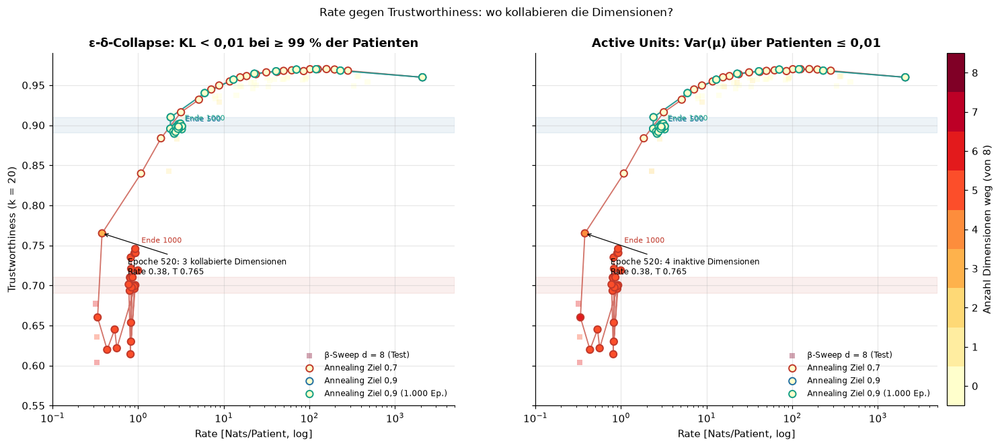

run,epoch,rate,trustworthiness,collapsed_dimensions,inactive_units
"Ziel 0,7",20,612.874542,0.946572,0,1
"Ziel 0,7",40,518.150099,0.960309,0,1
"Ziel 0,7",60,1086.735268,0.959247,0,1
"Ziel 0,7",500,1.081315,0.839719,0,0
"Ziel 0,7",520,0.379047,0.765035,3,4
"Ziel 0,7",540,0.336096,0.660088,5,6
"Ziel 0,9",20,612.874542,0.946572,0,1
"Ziel 0,9",40,518.150099,0.960309,0,1
"Ziel 0,9",60,1086.735268,0.959247,0,1
"Ziel 0,9",500,3.017633,0.896944,0,0


In [9]:
units = (dimensions.assign(active=dimensions.mu_std ** 2 > 0.01).groupby(["run", "epoch"]).active.sum()
         .rename("active_units").reset_index())
rate_tw = snapshots.merge(units, on=["run", "epoch"])
rate_tw["inactive_units"] = 8 - rate_tw.active_units
sweep8 = sweep[sweep.latent_dim.eq(8)].assign(inactive_units=lambda f: 8 - f.posterior_active_units_count_eps_0p01)
CRITERIA = (("collapsed_dimensions", COLLAPSED, "ε-δ-Collapse: KL < 0,01 bei ≥ 99 % der Patienten", "kollabierte Dimensionen"),
            ("inactive_units", "inactive_units", "Active Units: Var(μ) über Patienten ≤ 0,01", "inaktive Dimensionen"))
cmap = plt.get_cmap("YlOrRd", 9)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), sharey=True)
for ax, (column, sweep_column, title, label) in zip(axes, CRITERIA):
    ax.scatter(sweep8.rate, sweep8.geometry_mu_trustworthiness_zadu_k20, c=sweep8[sweep_column], cmap=cmap,
               vmin=-.5, vmax=8.5, marker="s", s=28, alpha=.35, edgecolor="none", label="β-Sweep d = 8 (Test)")
    for run, group in rate_tw.groupby("run", sort=False):
        group = group[group.epoch >= REFERENCE_EPOCH].sort_values("epoch")
        ax.plot(group.rate, group.trustworthiness, "-", color=RUN_COLORS[run], lw=1.2, alpha=.7)
        points = ax.scatter(group.rate, group.trustworthiness, c=group[column], cmap=cmap, vmin=-.5, vmax=8.5,
                            s=46, edgecolor=RUN_COLORS[run], linewidth=1.3, zorder=3, label=f"Annealing {run}")
        onset = group[group[column] > 0]
        if len(onset):
            first = onset.iloc[0]
            ax.annotate(f"Epoche {first.epoch:.0f}: {first[column]:.0f} {label}\nRate {first.rate:.2f}, T {first.trustworthiness:.3f}",
                        (first.rate, first.trustworthiness), xytext=(25, -40), textcoords="offset points", fontsize=8,
                        arrowprops=dict(arrowstyle="->", color="black", lw=.8))
        end = group.iloc[-1]
        ax.annotate(f"Ende {end.epoch:.0f}", (end.rate, end.trustworthiness), xytext=(6, 6), textcoords="offset points",
                    fontsize=7, color=RUN_COLORS[run])
    for target, run in zip((.7, .9), RUN_COLORS):
        ax.axhspan(target - .01, target + .01, color=RUN_COLORS[run], alpha=.08)
    ax.set(xscale="log", xlabel="Rate [Nats/Patient, log]", title=title, xlim=(.1, 5e3), ylim=(.55, .99))
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("Trustworthiness (k = 20)")
colorbar = fig.colorbar(points, ax=axes, ticks=range(9), pad=.01, fraction=.025)
colorbar.set_label("Anzahl Dimensionen weg (von 8)")
fig.suptitle("Rate gegen Trustworthiness: wo kollabieren die Dimensionen?", fontsize=11)
fig.savefig(COLLAPSE_ROOT / "rate_vs_trustworthiness_collapse.png", dpi=160, bbox_inches="tight"); plt.show()

agreement = rate_tw[["run", "epoch", "rate", "trustworthiness", "collapsed_dimensions", "inactive_units"]]
display(agreement[agreement.collapsed_dimensions.ne(agreement.inactive_units)
                  | agreement.epoch.isin(first_collapse.reindex(agreement.run).to_numpy() - 20)]
        .style.format(precision=3).format({"epoch": "{:.0f}"}).hide(axis="index")
        .set_caption("Snapshots, in denen die Kriterien abweichen, und der letzte Snapshot vor dem Collapse"))

### 2.6 Krebs-AUC: acht Präsentations-Krebsarten gegen alle 33, und Preservation vor dem AUC-Abfall

Übernommen aus `preservation_annealing_demo.ipynb` (Abschnitt 6): AUC auf z mit dem nativen AUTOENCODIX-Presplit-Evaluator
(logistische Regression auf Train, AUC auf Validation), einmal für alle 33 Krebsarten und einmal nur für die acht
Präsentations-Krebsarten (BRCA, COAD, LUAD, LUSC, OV, READ, UCEC, UCS). Die Werte stammen aus den gespeicherten
Sammeldateien der drei Läufe.

Die Tabelle darunter fragt: Wie viel war von jeder Preservation-Metrik (relativ zum Warm-up-Ende) noch übrig, im letzten
Snapshot, bevor die AUC erstmals um 5 % unter ihren Warm-up-Wert fiel? Werte nahe 100 % heißen: Die Metrik hat den
AUC-Verlust nicht angekündigt. Nachträgliche Analyse, keine Schwellenoptimierung.

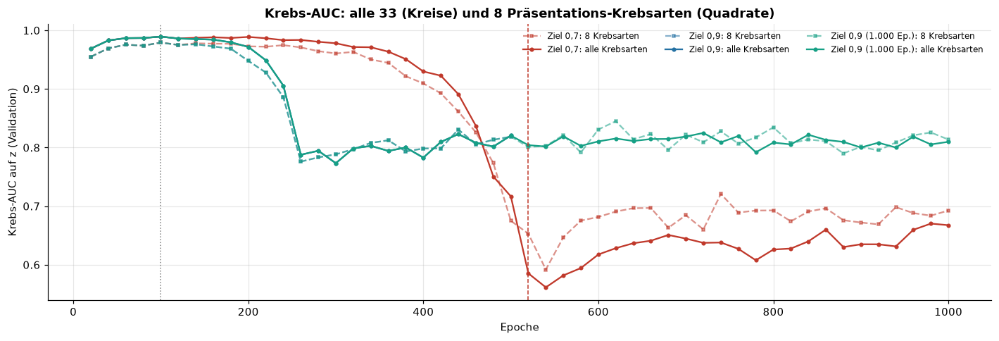

run,cohort,auc_abfall_ab,letzter_davor,beta_over_d_davor,status,trustworthiness_%,mrre_false_%,lcmc_%
"Ziel 0,7",8 Krebsarten,380,360,1.94e-04,Abfall beobachtet,99.997622,99.567461,95.089109
"Ziel 0,7",alle Krebsarten,400,380,2.84e-04,Abfall beobachtet,99.462596,98.900993,89.227722
"Ziel 0,9",8 Krebsarten,220,200,1.04e-04,Abfall beobachtet,100.473758,100.038521,100.056577
"Ziel 0,9",alle Krebsarten,240,220,2.54e-04,Abfall beobachtet,99.702178,99.193725,90.992927
"Ziel 0,9 (1.000 Ep.)",8 Krebsarten,220,200,1.04e-04,Abfall beobachtet,100.473758,100.038521,100.056577
"Ziel 0,9 (1.000 Ep.)",alle Krebsarten,240,220,2.54e-04,Abfall beobachtet,99.702178,99.193725,90.992927


In [10]:
AUC_SOURCES = {"Ziel 0,7": FOCUS / "summary_target_0.70", "Ziel 0,9": FOCUS / "summary_target_0.90_500ep",
               "Ziel 0,9 (1.000 Ep.)": FOCUS}
cohort_auc = pd.concat([pd.read_csv(folder / "tcga_pilot_cancer_auc.csv").assign(run=run)
                        for run, folder in AUC_SOURCES.items()])
fig, ax = plt.subplots(figsize=(13, 4.5))
for (run, cohort), group in cohort_auc.groupby(["run", "cohort"], sort=False):
    ax.plot(group.epoch, group.auc, "o-" if cohort == "alle Krebsarten" else "s--", ms=3, color=RUN_COLORS[run],
            alpha=1 if cohort == "alle Krebsarten" else .55, label=f"{run}: {cohort}")
for run, epoch in first_collapse.items():
    ax.axvline(epoch, color=RUN_COLORS[run], ls="--", lw=1)
ax.axvline(REFERENCE_EPOCH, color="gray", ls=":", lw=1)
ax.set(xlabel="Epoche", ylabel="Krebs-AUC auf z (Validation)", title="Krebs-AUC: alle 33 (Kreise) und 8 Präsentations-Krebsarten (Quadrate)")
ax.legend(fontsize=8, ncol=3)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "cancer_auc_8_vs_33.png", dpi=150); plt.show()

retention_rows = []
for (run, cohort), group in cohort_auc[cohort_auc.status.eq("ok")].groupby(["run", "cohort"], sort=False):
    group = group[group.epoch >= REFERENCE_EPOCH].sort_values("epoch")
    baseline = group.iloc[0]
    drops = group[group.auc < .95 * baseline.auc]
    if drops.empty:
        retention_rows.append(dict(run=run, cohort=cohort, status="kein 5 %-Abfall"))
        continue
    before = group[group.epoch < drops.iloc[0].epoch].iloc[-1]
    metrics = snapshots[snapshots.run.eq(run)].set_index("epoch")
    row = dict(run=run, cohort=cohort, auc_abfall_ab=int(drops.iloc[0].epoch), letzter_davor=int(before.epoch),
               beta_over_d_davor=metrics.loc[before.epoch, "beta_over_d"], status="Abfall beobachtet")
    for metric in ("trustworthiness", "mrre_false", "lcmc"):
        row[f"{metric}_%"] = 100 * metrics.loc[before.epoch, metric] / metrics.loc[baseline.epoch, metric]
    retention_rows.append(row)
retention = pd.DataFrame(retention_rows)
retention.to_csv(COLLAPSE_ROOT / "preservation_before_auc_drop.csv", index=False)
display(retention.style.format(precision=1, na_rep="–").format({"beta_over_d_davor": "{:.2e}"}, na_rep="–").hide(axis="index"))

## 3. Topologie-Pipeline auf dem Collapse-Verlauf

Dieselben Snapshots, ausgewertet mit der Topologie-Pipeline des Projekts (`metrics/topology`), auf dem festen
Controller-Subset (800 Validierungspatienten; X und μ paarweise ausgerichtet):

- **X↔μ-Vergleich (durchmesser-normiert):** Ripser auf D/max(D) je Raum (`RIPSER_CONFIG`: maxdim = 1, coeff = 2, thresh = ∞),
  dann Wasserstein W1 (persim) und Bottleneck (GUDHI) für H0 und H1 (`compute_persistence_diagrams_h0_h1`,
  `compute_normalized_wasserstein_h0_h1`, `compute_normalized_bottleneck_h0_h1`). Kleiner = Form besser erhalten.
  Diese Normierung entfernt die Kontraktion absichtlich und misst nur die relative Form.
- **Deskriptoren von μ:** Persistenz-Entropie H0/H1 (`compute_persistence_entropy`) und Balkenstatistik
  (`summarize_persistence_diagrams`); X dient als Referenz.
- **Feste Skala (Rauscheinheiten):** Ripser auf μ / 2,01 (2σ bei der logvar-Klemme), thresh = 3. Gezählt werden die
  H0-Komponenten und lebenden H1-Schleifen bei t = 1. Eine Komponente bei t = 1 heißt: Patienten, die mehr als
  2σ Rauschen voneinander entfernt sind. Das misst Unterscheidbarkeit in z, nicht Form.

Patienten mit μ = 0 sind Punkte im Abstand 0; sie verschmelzen bei Filtrationswert 0 (Balken der Länge 0) und
zählen wie ein Punkt. Die Pipeline lässt Balken der Länge 0 in Zusammenfassungen weg.

In [11]:
from sklearn.metrics import pairwise_distances
from ripser import ripser
from beta_vae_experiments.metrics.topology.preservation import (
    RIPSER_CONFIG, compute_persistence_diagrams_h0_h1, compute_normalized_wasserstein_h0_h1,
    compute_normalized_bottleneck_h0_h1)
from beta_vae_experiments.metrics.topology.latent_descriptor import compute_persistence_entropy, summarize_persistence_diagrams

NOISE_UNIT = 2 * np.exp(0.5 * 0.01)
FS_THRESH, FS_T = 3.0, 1.0
TOPOLOGY_ROOT = COLLAPSE_ROOT / "topology"
TOPOLOGY_ROOT.mkdir(exist_ok=True)
topology_cache = TOPOLOGY_ROOT / "topology_snapshots.csv"
topology = pd.read_csv(topology_cache) if topology_cache.exists() else pd.DataFrame(columns=["run"])
missing_runs = [run for run in COLLAPSE_RUNS if run not in set(topology.run)]
if missing_runs:  # nur neue Läufe berechnen
    topology_rows = []
    for run in missing_runs:
        folder = run_folder(run)
        with np.load(folder / "controller_validation_reference.npz") as reference:
            x_reference, reference_ids = reference["x"].astype(np.float64), reference["sample_ids"].astype(str)
        dx = pairwise_distances(x_reference)
        input_diagrams = ripser(dx / dx.max(), **RIPSER_CONFIG)["dgms"]
        for path in sorted((folder / "epoch_snapshots").glob("epoch_*_valid.npz")):
            epoch = int(path.stem.split("_")[1])
            with np.load(path) as saved:
                positions = pd.Index(saved["sample_ids"].astype(str)).get_indexer(reference_ids)
                mu = saved["mu"][positions].astype(np.float64)
            row = dict(run=run, epoch=epoch, distinct_mu=len(np.unique(mu, axis=0)))
            dm = pairwise_distances(mu)
            if dm.max() > 1e-12:
                diagrams = compute_persistence_diagrams_h0_h1(dx, dm, dx.max(), dm.max(), input_diagrams)
                for table in (compute_normalized_wasserstein_h0_h1(diagrams, len(mu)),
                              compute_normalized_bottleneck_h0_h1(diagrams, len(mu)),
                              compute_persistence_entropy(diagrams, len(mu))):
                    row.update(dict(zip(table.metric_name, table.value)))
                bars = summarize_persistence_diagrams(diagrams)
                for _, bar in bars.iterrows():
                    row[f"{bar.space}_h{bar.homology_dimension}_bars"] = bar.n_finite_bars
                    row[f"{bar.space}_h{bar.homology_dimension}_total_persistence"] = bar.total_persistence
                if epoch % 100 == 0 or epoch in (first_collapse.get(run, -1), first_collapse.get(run, -1) - 20):
                    np.savez(TOPOLOGY_ROOT / f"diagrams_{COLLAPSE_RUNS[run]}_{epoch:05d}.npz", **diagrams)
            fixed = ripser(mu / NOISE_UNIT, maxdim=1, thresh=FS_THRESH)["dgms"]
            h0, h1 = fixed[0], fixed[1]
            row.update(fs_h0_components_t1=int(np.sum(h0[:, 1] > FS_T)),
                       fs_h1_loops_t1=int(np.sum((h1[:, 0] <= FS_T) & (h1[:, 1] > FS_T))) if len(h1) else 0,
                       fs_h0_nn_median=float(np.median(h0[np.isfinite(h0[:, 1]), 1])) if len(h0) > 1 else np.nan)
            topology_rows.append(row)
            print(run, epoch, "fertig", flush=True)
    topology = pd.concat([topology, pd.DataFrame(topology_rows)], ignore_index=True)
    topology.to_csv(topology_cache, index=False)
topology = topology[topology.run.isin(COLLAPSE_RUNS)].astype({"epoch": int})
topology = topology.merge(snapshots[["run", "epoch", "beta_over_d", "rate", "collapsed_dimensions", "zero_patients"]],
                          on=["run", "epoch"])
display(topology[topology.epoch.isin([REFERENCE_EPOCH, 300, 500, 520, 1000])].round(3))

,run,epoch,distinct_mu,topology_h0_normalized_wasserstein,topology_h1_normalized_wasserstein,topology_h0_normalized_bottleneck,topology_h1_normalized_bottleneck,topology_h0_persistence_entropy_x,topology_h0_persistence_entropy_mu,topology_h1_persistence_entropy_x,...,x_h1_total_persistence,mu_h1_bars,mu_h1_total_persistence,fs_h0_components_t1,fs_h1_loops_t1,fs_h0_nn_median,beta_over_d,rate,collapsed_dimensions,zero_patients
4,"Ziel 0,7",100,800,154.644,3.442,0.239,0.038,6.655,6.562,4.545,...,1.238,389,4.217,790,0,2.142,0.000,2093.645,0,0.000
14,"Ziel 0,7",300,800,147.546,3.107,0.206,0.042,6.655,6.526,4.545,...,1.238,295,4.152,116,30,0.622,0.000,31.390,0,0.000
24,"Ziel 0,7",500,688,155.798,1.071,0.244,0.021,6.655,5.736,4.545,...,1.238,44,0.317,1,0,0.015,0.003,1.081,0,0.141
25,"Ziel 0,7",520,593,154.782,0.921,0.244,0.021,6.655,5.198,4.545,...,1.238,15,0.066,1,0,0.002,0.004,0.379,3,0.269
49,"Ziel 0,7",1000,565,154.661,0.943,0.244,0.021,6.655,5.212,4.545,...,1.238,9,0.096,1,0,0.004,0.002,0.925,5,0.292
54,"Ziel 0,9",100,800,154.644,3.442,0.239,0.038,6.655,6.562,4.545,...,1.238,389,4.217,790,0,2.142,0.000,2093.645,0,0.000
64,"Ziel 0,9",300,763,156.617,1.744,0.243,0.041,6.655,6.126,4.545,...,1.238,124,1.429,1,1,0.055,0.001,2.564,0,0.049
74,"Ziel 0,9",500,767,157.446,1.548,0.244,0.023,6.655,6.106,4.545,...,1.238,104,1.099,1,0,0.062,0.001,3.018,0,0.044
79,"Ziel 0,9 (1.000 Ep.)",100,800,154.644,3.442,0.239,0.038,6.655,6.562,4.545,...,1.238,389,4.217,790,0,2.142,0.000,2093.645,0,0.000
89,"Ziel 0,9 (1.000 Ep.)",300,763,156.617,1.744,0.243,0.041,6.655,6.126,4.545,...,1.238,124,1.429,1,1,0.055,0.001,2.564,0,0.049


### 3.1 Verlauf der Topologie-Signale

Oben X↔μ-Abstände der Diagramme (durchmesser-normiert; steigend = Form geht verloren; H0 linke, H1 rechte Achse), Mitte Persistenz-Entropie von μ
(gestrichelt: X als Referenz), unten feste Skala: Anteil unterscheidbarer Komponenten bei t = 1 und H1-Schleifen bei t = 1.

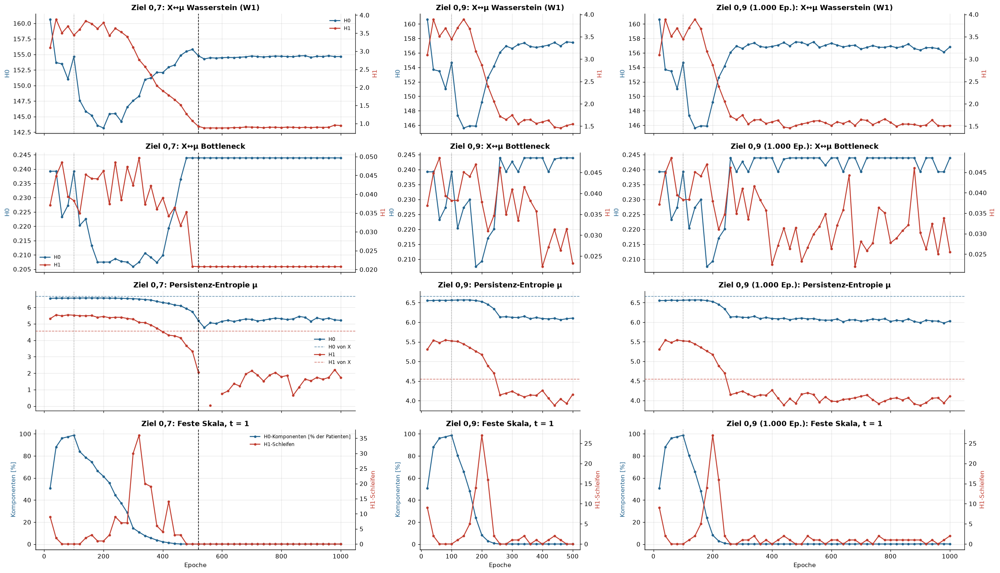

In [12]:
TOPO_PANELS = [
    ("X↔μ Wasserstein (W1)", [("topology_h0_normalized_wasserstein", "H0"), ("topology_h1_normalized_wasserstein", "H1")]),
    ("X↔μ Bottleneck", [("topology_h0_normalized_bottleneck", "H0"), ("topology_h1_normalized_bottleneck", "H1")]),
    ("Persistenz-Entropie μ", [("topology_h0_persistence_entropy_mu", "H0"), ("topology_h1_persistence_entropy_mu", "H1")]),
    ("Feste Skala, t = 1", [("fs_h0_components_share", "H0-Komponenten [% der Patienten]"), ("fs_h1_loops_t1", "H1-Schleifen")]),
]
topology["fs_h0_components_share"] = 100 * topology.fs_h0_components_t1 / 800
fig, axes = plt.subplots(len(TOPO_PANELS), NCOLS, figsize=(7.5 * NCOLS, 13), sharex="col", gridspec_kw=dict(width_ratios=WIDTHS))
for column_index, run in enumerate(COLLAPSE_RUNS):
    group = topology[topology.run.eq(run)].sort_values("epoch")
    for row_index, (title, series) in enumerate(TOPO_PANELS):
        ax = axes[row_index, column_index]
        twin = ax.twinx() if row_index in (0, 1, 3) else None
        for (column, label), color, target in zip(series, ("#1f618d", "#c0392b"), (ax, twin or ax)):
            target.plot(group.epoch, group[column], "o-", ms=3, color=color, label=label)
            if row_index == 2:
                reference = group[column.replace("_mu", "_x")].median()
                ax.axhline(reference, color=color, ls="--", lw=1, alpha=.7, label=f"{label} von X")
        if twin is not None:
            twin.set_ylabel("H1-Schleifen" if row_index == 3 else "H1", color="#c0392b")
            twin.spines["right"].set_visible(True); twin.grid(False)
            ax.set_ylabel("Komponenten [%]" if row_index == 3 else "H0", color="#1f618d")
        if run in first_collapse:
            ax.axvline(first_collapse[run], color="black", ls="--", lw=1)
        ax.axvline(REFERENCE_EPOCH, color="gray", ls=":", lw=1)
        ax.set_title(f"{run}: {title}")
        if column_index == 0:
            handles = ax.get_legend_handles_labels()[0] + (twin.get_legend_handles_labels()[0] if twin else [])
            ax.legend(handles=handles, fontsize=8, loc="best")
    axes[-1, column_index].set_xlabel("Epoche")
fig.tight_layout(); fig.savefig(TOPOLOGY_ROOT / "topology_over_epochs.png", dpi=160); plt.show()

### 3.2 Persistenzdiagramme vor, beim und nach dem Collapse

H1-Diagramme (Geburt gegen Tod, durchmesser-normiert) von X (grau) und μ (farbig) im kollabierenden Lauf an vier Zeitpunkten,
darunter die H0-Todeszeiten von μ (wann verschmelzen Patienten zu einer Komponente). Identische μ (z. B. Patienten
bei μ = 0) verschmelzen bei 0; Ripser gibt Balken der Länge 0 nicht aus, deshalb steht ihre Zahl im Titel
(800 minus Zahl verschiedener μ). Viele Punkte nahe der Diagonale sind
kurzlebige Schleifen (Rauschen); weit oben liegende sind persistente Strukturen.

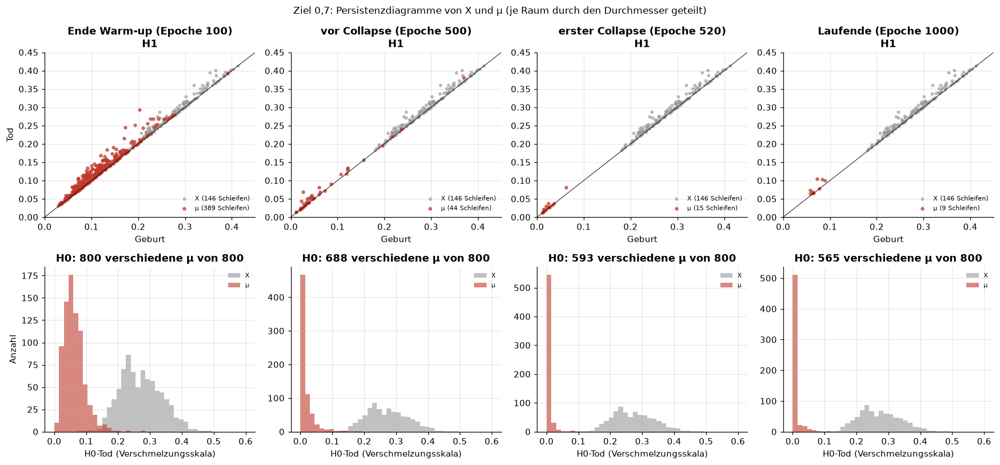

In [13]:
run = "Ziel 0,7"
moments = {"Ende Warm-up": REFERENCE_EPOCH, "vor Collapse": first_collapse[run] - 20,
           "erster Collapse": first_collapse[run], "Laufende": snapshots[snapshots.run.eq(run)].epoch.max()}
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for column_index, (moment, epoch) in enumerate(moments.items()):
    path = TOPOLOGY_ROOT / f"diagrams_{COLLAPSE_RUNS[run]}_{epoch:05d}.npz"
    with np.load(path) as saved:
        x_h1, mu_h1 = saved["topology_input_h1_persistence_diagram"], saved["topology_latent_h1_persistence_diagram"]
        x_h0, mu_h0 = saved["topology_input_h0_persistence_diagram"], saved["topology_latent_h0_persistence_diagram"]
    ax = axes[0, column_index]
    ax.scatter(x_h1[:, 0], x_h1[:, 1], s=8, color="#999999", alpha=.6, label=f"X ({len(x_h1)} Schleifen)")
    ax.scatter(mu_h1[:, 0], mu_h1[:, 1], s=10, color=RUN_COLORS[run], alpha=.7, label=f"μ ({len(mu_h1)} Schleifen)")
    ax.plot([0, 1], [0, 1], color="black", lw=.6)
    ax.set(xlim=(0, .45), ylim=(0, .45), xlabel="Geburt", ylabel="Tod" if column_index == 0 else None,
           title=f"{moment} (Epoche {epoch})\nH1")
    ax.legend(fontsize=7, loc="lower right")
    ax = axes[1, column_index]
    finite_mu, finite_x = mu_h0[np.isfinite(mu_h0[:, 1]), 1], x_h0[np.isfinite(x_h0[:, 1]), 1]
    bins = np.linspace(0, .6, 41)
    ax.hist(finite_x, bins=bins, color="#999999", alpha=.6, label="X")
    ax.hist(finite_mu, bins=bins, color=RUN_COLORS[run], alpha=.6, label="μ")
    distinct = topology[(topology.run == run) & (topology.epoch == epoch)].distinct_mu.iloc[0]
    ax.set(xlabel="H0-Tod (Verschmelzungsskala)", ylabel="Anzahl" if column_index == 0 else None,
           title=f"H0: {distinct} verschiedene μ von 800")
    ax.legend(fontsize=7)
fig.suptitle(f"{run}: Persistenzdiagramme von X und μ (je Raum durch den Durchmesser geteilt)", fontsize=11)
fig.tight_layout(); fig.savefig(TOPOLOGY_ROOT / "persistence_diagrams_collapse.png", dpi=160); plt.show()

### 3.3 Wo stehen die Topologie-Signale in der Zerstörungsreihenfolge?

Wie in 8.1: erste Snapshot-Epoche, ab der sich ein Signal gegenüber dem Warm-up-Ende um 5 % bzw. 20 % verschlechtert.
Für Wasserstein/Bottleneck heißt verschlechtern: steigen; für die Komponenten bei fester Skala: fallen. Die Entropie hat
keine eindeutig gute Richtung, gezählt wird deshalb die absolute relative Änderung. Zum Vergleich stehen die Zeitpunkte
aus 8.1 (Trustworthiness, AUC, Dimensionen) mit in der Tabelle.

run,signal,quelle,epoch_5%,epoch_20%,referenz
"Ziel 0,7",Komponenten bei t = 1,Topologie,120.000000,140.000000,790.000
"Ziel 0,7",Bottleneck H1 X↔μ,Topologie,140.000000,200.000000,0.038
"Ziel 0,7",W1 H1 X↔μ,Topologie,140.000000,–,3.442
"Ziel 0,7",Rekonstruktionsfehler,Abschnitt 2.1,200.000000,320.000000,–
"Ziel 0,7",Entropie H1 μ,Topologie,320.000000,420.000000,5.521
"Ziel 0,7",AUC Geschlecht,Abschnitt 2.1,320.000000,460.000000,–
"Ziel 0,7",Cohesiveness,Abschnitt 2.1,340.000000,–,–
"Ziel 0,7",LCMC,Abschnitt 2.1,380.000000,440.000000,–
"Ziel 0,7",AUC Krebsart,Abschnitt 2.1,400.000000,480.000000,–
"Ziel 0,7",Entropie H0 μ,Topologie,440.000000,520.000000,6.562


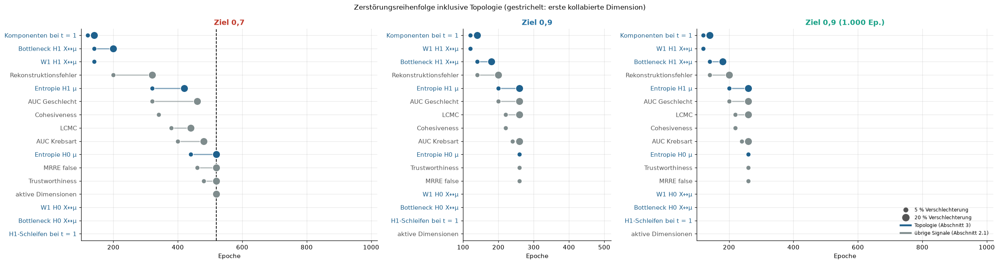

In [14]:
TOPO_SIGNALS = {"topology_h0_normalized_wasserstein": ("W1 H0 X↔μ", -1), "topology_h1_normalized_wasserstein": ("W1 H1 X↔μ", -1),
                "topology_h0_normalized_bottleneck": ("Bottleneck H0 X↔μ", -1), "topology_h1_normalized_bottleneck": ("Bottleneck H1 X↔μ", -1),
                "topology_h0_persistence_entropy_mu": ("Entropie H0 μ", 0), "topology_h1_persistence_entropy_mu": ("Entropie H1 μ", 0),
                "fs_h0_components_t1": ("Komponenten bei t = 1", +1), "fs_h1_loops_t1": ("H1-Schleifen bei t = 1", 0)}
rows = []
for run, group in topology.groupby("run"):
    group = group[group.epoch >= REFERENCE_EPOCH].sort_values("epoch").reset_index(drop=True)
    for column, (label, direction) in TOPO_SIGNALS.items():
        reference = group.loc[group.epoch.eq(REFERENCE_EPOCH), column].iloc[0]
        change = (group[column] - reference) / abs(reference) if reference != 0 else group[column] * np.nan
        loss = change.abs() if direction == 0 else (-change if direction > 0 else change)
        row = dict(run=run, signal=label, quelle="Topologie")
        for threshold in (0.05, 0.20):
            hit = group[loss >= threshold]
            row[f"epoch_{threshold:.0%}"] = hit.epoch.iloc[0] if len(hit) else np.nan
        row["referenz"] = reference
        rows.append(row)
combined = pd.concat([pd.DataFrame(rows), destruction_order.assign(quelle="Abschnitt 2.1")[["run", "signal", "quelle", "epoch_5%", "epoch_20%"]]])
combined = combined.sort_values(["run", "epoch_5%", "epoch_20%"], na_position="last")
combined.to_csv(TOPOLOGY_ROOT / "destruction_order_with_topology.csv", index=False)
display(combined.style.format(precision=0, na_rep="–").format({"referenz": "{:.3f}"}, na_rep="–").hide(axis="index"))

fig, axes = plt.subplots(1, NCOLS, figsize=(7.5 * NCOLS, 6), gridspec_kw=dict(width_ratios=WIDTHS))
for ax, run in zip(axes, COLLAPSE_RUNS):
    table = combined[combined.run.eq(run)].reset_index(drop=True)
    for y, row in table.iterrows():
        color = "#1f618d" if row.quelle == "Topologie" else "#7f8c8d"
        for column, size in (("epoch_5%", 60), ("epoch_20%", 150)):
            if np.isfinite(row[column]):
                ax.scatter(row[column], y, s=size, color=color, edgecolor="white", zorder=3)
        if np.isfinite(row["epoch_5%"]) and np.isfinite(row["epoch_20%"]):
            ax.plot([row["epoch_5%"], row["epoch_20%"]], [y, y], color=color, lw=2, alpha=.5)
    if run in first_collapse:
        ax.axvline(first_collapse[run], color="black", ls="--", lw=1.2)
    ax.set(yticks=range(len(table)), yticklabels=table.signal, ylim=(len(table) - .5, -.5),
           xlim=(REFERENCE_EPOCH, snapshots[snapshots.run.eq(run)].epoch.max() + 20), xlabel="Epoche", title=run)
    ax.title.set_color(RUN_COLORS[run])
    for label, row in zip(ax.get_yticklabels(), table.itertuples()):
        label.set_color("#1f618d" if row.quelle == "Topologie" else "#555555")
legend = [Line2D([], [], ls="", marker="o", ms=7, color="#555555", label="5 % Verschlechterung"),
          Line2D([], [], ls="", marker="o", ms=11, color="#555555", label="20 % Verschlechterung"),
          Line2D([], [], color="#1f618d", lw=3, label="Topologie (Abschnitt 3)"),
          Line2D([], [], color="#7f8c8d", lw=3, label="übrige Signale (Abschnitt 2.1)")]
axes[-1].legend(handles=legend, fontsize=8, loc="lower right")
fig.suptitle("Zerstörungsreihenfolge inklusive Topologie (gestrichelt: erste kollabierte Dimension)", fontsize=11)
fig.tight_layout(); fig.savefig(TOPOLOGY_ROOT / "destruction_order_with_topology.png", dpi=160); plt.show()

## 4. UMAP aus AUTOENCODIX

AUTOENCODIX zeichnet den Latentraum mit `show_latent_space`: `UMAP(n_components=2)` auf dem gespeicherten Latentraum z
und `GeneralVisualizer._plot_2D` für das Streudiagramm (Gruppenmittelwerte als große Punkte). Unsere Läufe speichern kein
AUTOENCODIX-`Result`-Objekt, deshalb werden genau diese beiden Bausteine direkt auf die z-Snapshots angewendet
(Train + Validation, wie `split="all"`). Einzige Abweichung: `random_state=0` für reproduzierbare UMAPs.
Pro Lauf vier Zeitpunkte: Ende Warm-up, letzter Snapshot vor dem Collapse (bzw. Epoche 260, wenn der Lauf das Zielband erreicht),
erster Collapse (bzw. Mitte) und Laufende. Gefärbt nach den acht Präsentations-Krebsarten (übrige grau) und nach Geschlecht.

Achtung bei der Interpretation: UMAP ist nichtlinear und zeigt lokale Nachbarschaft, keine Abstände; Größe und Lage
der Wolken sind zwischen Panels nicht vergleichbar. Kollabierte Dimensionen sind in z reines N(0,1)-Rauschen und
verwischen die UMAP zusätzlich.

/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to

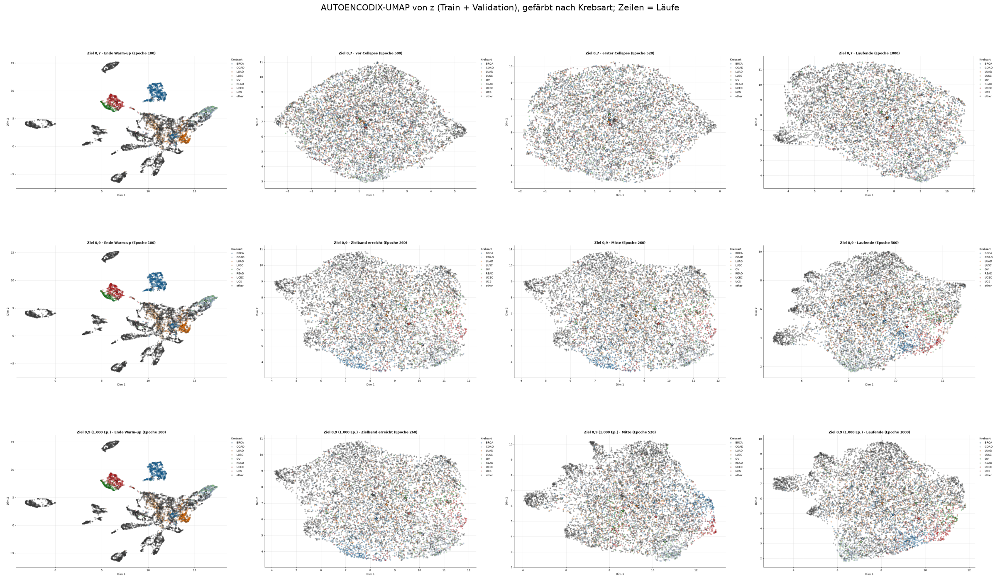

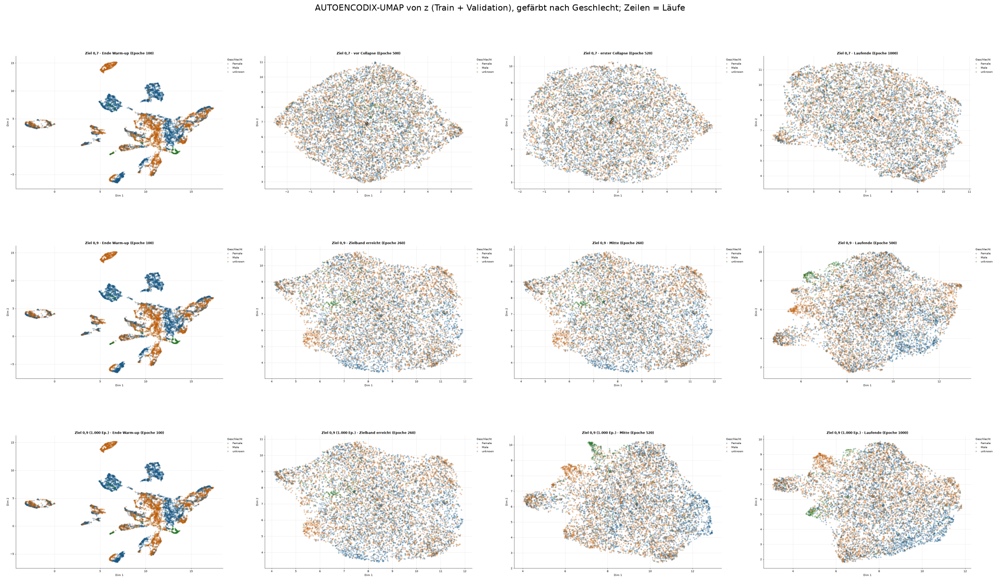

In [15]:
import io
import warnings as _warnings
from umap import UMAP
from autoencodix.visualize._general_visualizer import GeneralVisualizer

PRESENTATION = ("BRCA", "COAD", "LUAD", "LUSC", "OV", "READ", "UCEC", "UCS")


def umap_moments(run):
    epochs = sorted(snapshots[snapshots.run.eq(run)].epoch)
    if run in first_collapse:
        chosen = [REFERENCE_EPOCH, first_collapse[run] - 20, first_collapse[run], epochs[-1]]
        names = ["Ende Warm-up", "vor Collapse", "erster Collapse", "Laufende"]
    else:
        chosen = [REFERENCE_EPOCH, 260, epochs[len(epochs) // 2], epochs[-1]]
        names = ["Ende Warm-up", "Zielband erreicht", "Mitte", "Laufende"]
    return dict(zip(names, chosen))


def load_z(run, epoch):
    folder = run_folder(run)
    frames, label_frames = [], []
    for split in ("train", "valid"):
        with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_{split}.npz") as saved:
            frames.append(pd.DataFrame(saved["z"], index=saved["sample_ids"].astype(str)))
        labels = pd.read_parquet(folder / "epoch_snapshots" / f"labels_{split}.parquet")
        labels.index = labels.index.astype(str)
        label_frames.append(labels.loc[frames[-1].index, ["CANCER_TYPE_ACRONYM", "SEX"]])
    return pd.concat(frames), pd.concat(label_frames)


def figure_to_image(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=70, bbox_inches="tight")
    plt.close(figure)
    buffer.seek(0)
    return plt.imread(buffer)


umap_images = {}
for run in COLLAPSE_RUNS:
    for moment, epoch in umap_moments(run).items():
        z, labels = load_z(run, epoch)
        embedding = pd.DataFrame(UMAP(n_components=2, random_state=0).fit_transform(z), index=z.index)
        for param, values, focus in (("Krebsart", labels.CANCER_TYPE_ACRONYM.fillna("unknown"), list(PRESENTATION)),
                                     ("Geschlecht", labels.SEX.fillna("unknown"), None)):
            with _warnings.catch_warnings():
                _warnings.simplefilter("ignore")
                figure = GeneralVisualizer._plot_2D(embedding=embedding.reset_index(drop=True), labels=values.tolist(),
                                                    focus_labels=focus, param=param,
                                                    layer=f"{run} · {moment} (Epoche {epoch})", figsize=(12, 8), center=True)
            umap_images[(param, run, moment)] = figure_to_image(figure)

for param in ("Krebsart", "Geschlecht"):
    fig, axes = plt.subplots(NCOLS, 4, figsize=(22, 4.6 * NCOLS))
    for row, run in enumerate(COLLAPSE_RUNS):
        for column, moment in enumerate(umap_moments(run)):
            ax = axes[row, column]
            ax.imshow(umap_images[(param, run, moment)])
            ax.set_axis_off()
    fig.suptitle(f"AUTOENCODIX-UMAP von z (Train + Validation), gefärbt nach {param}; Zeilen = Läufe", fontsize=13)
    fig.tight_layout()
    fig.savefig(COLLAPSE_ROOT / f"umap_autoencodix_{'cancer' if param == 'Krebsart' else 'sex'}.png", dpi=130)
    plt.show()

## 5. Preservation über alle Skalen: k-Sweep und Co-Ranking

Bisher wurde jede Preservation-Metrik bei einem festen k = 20 gemessen. LCMC (k = 20) reagiert früh, Trustworthiness
(k = 20) spät; ob das an der Metrik oder an der Skala liegt, zeigt erst ein Sweep über k. Grundlage ist das
Co-Ranking-Framework von Lee & Verleysen (2009): Für jedes k misst **R_NX(k)** den Anteil der k-Nachbarschaften,
der von X nach μ erhalten bleibt, bereinigt um den Zufallswert (0 = Zufall, 1 = perfekt).

Umsetzung ohne eigene Metrikformeln:
- **R_NX(k)** aus ZADUs LCMC: LCMC(k) = Q_NX(k) − k/(n−1), daraus R_NX(k) = (n−1)·LCMC(k) / (n−1−k).
- **Trustworthiness und Continuity für jedes k** aus ZADU `trustworthiness_continuity` (nur für k < n/2 definiert).
- **MRRE false und MRRE missing für jedes k** aus ZADU `mean_relative_rank_error` (false = falsche Nachbarn in μ,
  Gegenstück zu Trustworthiness; missing = verlorene Nachbarn aus X, Gegenstück zu Continuity).
- Alle Nachbarlisten mit dem Punkt selbst an erster Stelle (`_self_first_neighbours` aus `preservation_annealing.py`),
  damit Duplikate bei μ = 0 nichts verfälschen.
- **Skalenübergreifender Wert:** AUC_logk = Σ R_NX(k)/k / Σ 1/k über das k-Raster (diskrete Näherung der
  log-gewichteten Fläche von Lee et al. 2015, die über alle k = 1 … n−2 summiert).
- **Globale Gegenstücke aus ZADU:** Spearman-Korrelation aller Paardistanzen, Distance-to-Measure und KL-Divergenz
  der Dichteschätzungen (σ = 0,1 und 1; ZADU normiert die Distanzen intern).

**k-Raster:** n = 800 Patienten (festes Controller-Subset). Feste kleine Werte 5, 10, 20, die Anteile 1 % (8), 5 % (40),
10 % (80), 25 % (200) und ein logarithmisches Raster von 2 bis 798. Die Krebsarten-Größen spielen hier keine direkte Rolle,
weil die Nachbarschaften über alle Patienten gebildet werden; erst ab k größer als eine Klasse (z. B. CHOL mit 3
Validierungspatienten) enthält jede Nachbarschaft zwangsläufig fremde Klassen.

**Die Rausch-Hypothese.** Vorschlag: Eine Nachbarschaft der Größe k zerfällt, wenn die Posterior-σ den typischen
k-NN-Radius überschreitet. In unserem Modell ist σ wegen der logvar-Klemme fest (≈ 1,005); was sich mit β ändert, ist die
Skala von μ. Auf μ selbst kann σ keine Nachbarschaft zerstören, weil μ kein Rauschen enthält. Testbar wird die Hypothese
auf **z = μ + σ·ε**: Gemessen wird der k-NN-Radius von μ in Rauscheinheiten (μ / 2σ, wie in Abschnitt 3). Ist der
mediane Abstand zum k-ten Nachbarn kleiner als 1, liegen die k Nachbarn innerhalb des Rauschens. Vorhersage:
R_NX auf z bricht genau für die k ein, deren Radius unter 1 liegt (k_noise), während R_NX auf μ dort noch hoch sein kann.

Gerechnet wird alle 40 Epochen sowie um den Collapse und um den Trustworthiness-Stopp herum, für den kollabierenden Lauf (Ziel 0,7) und den
1.000-Epochen-Lauf (Ziel 0,9); der 500-Epochen-Lauf ist bis Epoche 500 identisch.

In [16]:
from zadu.measures import (trustworthiness_continuity, local_continuity_meta_criteria, mean_relative_rank_error,
                           spearman_rho, distance_to_measure, kl_divergence)
from zadu.measures.utils.pairwise_dist import pairwise_distance_matrix
from beta_vae_experiments.preservation_annealing import _self_first_neighbours

N_REFERENCE = 800
K_GRID = sorted({5, 10, 20, 8, 40, 80, 200, *np.unique(np.geomspace(2, N_REFERENCE - 2, 24).astype(int)).tolist()})
K_TC = [k for k in K_GRID if k < N_REFERENCE / 2]
SWEEP_RUNS = ["Ziel 0,7", "Ziel 0,9 (1.000 Ep.)"]
SIGMAS = (0.1, 1.0)


def stop_snapshots(run):
    """Erste Controller-Messung im Zustand 'hold' und die Snapshots direkt davor und danach."""
    controller = pd.read_csv(run_folder(run) / "controller_log.csv")
    stop = int(controller[controller.state.eq("hold")].epoch.min())
    epochs = sorted(snapshots[snapshots.run.eq(run)].epoch)
    before = [e for e in epochs if e < stop]
    return dict(stop_epoch=stop, before_2=before[-2], before=before[-1], after=min(e for e in epochs if e >= stop))


def sweep_epochs(run):
    epochs = set(snapshots[snapshots.run.eq(run)].epoch)
    chosen = {e for e in epochs if e >= REFERENCE_EPOCH and (e - REFERENCE_EPOCH) % 40 == 0}
    if run in first_collapse:
        chosen |= {first_collapse[run] - 20, first_collapse[run], first_collapse[run] + 20}
    chosen |= {v for key, v in stop_snapshots(run).items() if key != "stop_epoch"}
    return sorted(chosen & epochs)


ksweep_cache, global_cache = COLLAPSE_ROOT / "k_sweep.csv", COLLAPSE_ROOT / "k_sweep_global.csv"
if ksweep_cache.exists() and global_cache.exists() and "mrre_false" in pd.read_csv(ksweep_cache, nrows=1):
    k_sweep, global_measures = pd.read_csv(ksweep_cache), pd.read_csv(global_cache)
else:
    k_rows, global_rows = [], []
    for run in SWEEP_RUNS:
        folder = run_folder(run)
        with np.load(folder / "controller_validation_reference.npz") as reference:
            x_reference, reference_ids = reference["x"].astype(np.float64), reference["sample_ids"].astype(str)
        n = len(x_reference)
        x_neighbours, x_ranking = _self_first_neighbours(x_reference, n - 1)
        x_distances = np.array(pairwise_distance_matrix(x_reference, "euclidean"), dtype=np.float64)
        for epoch in sweep_epochs(run):
            with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_valid.npz") as saved:
                positions = pd.Index(saved["sample_ids"].astype(str)).get_indexer(reference_ids)
                spaces = {"μ": saved["mu"][positions].astype(np.float64), "z": saved["z"][positions].astype(np.float64)}
            for space, values in spaces.items():
                neighbours, ranking = _self_first_neighbours(values, n - 1)
                distances = np.array(pairwise_distance_matrix(values, "euclidean"), dtype=np.float64)
                sorted_noise = np.sort(distances / NOISE_UNIT, axis=1)  # Spalte 0 = selbst
                for k in K_GRID:
                    lcmc = local_continuity_meta_criteria.measure(x_reference, values, k=k,
                                                                  knn_info=(x_neighbours[:, :k], neighbours[:, :k]))["lcmc"]
                    mrre = mean_relative_rank_error.measure(
                        x_reference, values, k=k, knn_ranking_info=(x_neighbours[:, :k], x_ranking, neighbours[:, :k], ranking))
                    row = dict(run=run, epoch=epoch, space=space, k=k, r_nx=(n - 1) * lcmc / (n - 1 - k),
                               mrre_false=mrre["mrre_false"], mrre_missing=mrre["mrre_missing"],
                               knn_radius_noise=float(np.median(sorted_noise[:, k])))
                    if k in K_TC:
                        tc = trustworthiness_continuity.measure(
                            x_reference, values, k=k,
                            knn_ranking_info=(x_neighbours[:, :k], x_ranking, neighbours[:, :k], ranking))
                        row.update(trustworthiness=tc["trustworthiness"], continuity=tc["continuity"])
                    k_rows.append(row)
                global_row = dict(run=run, epoch=epoch, space=space,
                                  spearman=spearman_rho.measure(x_reference, values, distance_matrices=(x_distances, distances))["spearman_rho"])
                for sigma in SIGMAS:
                    global_row[f"dtm_{sigma:g}"] = distance_to_measure.measure(
                        x_reference, values, sigma=sigma, distance_matrices=(x_distances, distances))["distance_to_measure"]
                    global_row[f"kl_{sigma:g}"] = kl_divergence.measure(
                        x_reference, values, sigma=sigma, distance_matrices=(x_distances, distances))["kl_divergence"]
                global_rows.append(global_row)
            print(run, epoch, "fertig", flush=True)
    k_sweep, global_measures = pd.DataFrame(k_rows), pd.DataFrame(global_rows)
    k_sweep.to_csv(ksweep_cache, index=False)
    global_measures.to_csv(global_cache, index=False)

weights = k_sweep.drop_duplicates("k").set_index("k").index.to_series().rdiv(1.0)
auc_logk = (k_sweep.assign(weighted=k_sweep.r_nx / k_sweep.k).groupby(["run", "epoch", "space"]).weighted.sum()
            / weights.sum()).rename("auc_logk").reset_index()
global_measures = global_measures.merge(auc_logk, on=["run", "epoch", "space"])
noise_k = (k_sweep[k_sweep.space.eq("μ") & (k_sweep.knn_radius_noise <= 1)].groupby(["run", "epoch"]).k.max()
           .rename("k_noise").reset_index())
display(global_measures.merge(noise_k, on=["run", "epoch"], how="left").sort_values("epoch")
        .groupby(["run", "space"]).tail(1).round(3).style.format(precision=3).hide(axis="index")
        .set_caption("Letzter Snapshot je Lauf und Raum"))

run,epoch,space,spearman,dtm_0.1,kl_0.1,dtm_1,kl_1,auc_logk,k_noise
"Ziel 0,7",980,z,0.208,0.424,0.142,0.052,0.002,0.013,615.000
"Ziel 0,7",980,μ,0.528,0.371,0.113,0.050,0.003,0.066,615.000
"Ziel 0,9 (1.000 Ep.)",980,μ,0.738,0.296,0.079,0.039,0.001,0.192,217.000
"Ziel 0,9 (1.000 Ep.)",980,z,0.403,0.372,0.113,0.047,0.002,0.040,217.000


### 5.1 R_NX(k)-Kurven: Auf welcher Skala bricht die Struktur zuerst?

Oben μ, unten z; links der kollabierende Lauf, rechts der 1.000-Epochen-Lauf. Jede Kurve ist ein Snapshot (Farbe =
Epoche, hell = früh). Eine Kurve, die nur links (kleine k) fällt, verliert lokale Struktur bei erhaltener globaler Ordnung;
eine Kurve, die überall fällt, verliert beides.

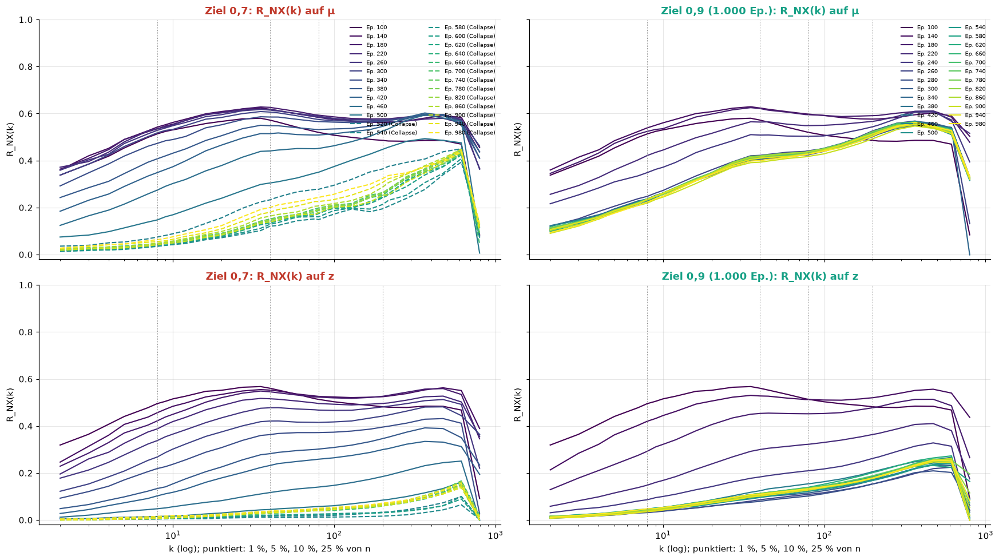

In [17]:
fig, axes = plt.subplots(2, len(SWEEP_RUNS), figsize=(8 * len(SWEEP_RUNS), 9), sharex=True, sharey="row")
for column, run in enumerate(SWEEP_RUNS):
    epochs = sweep_epochs(run)
    colors = plt.cm.viridis(np.linspace(0, 1, len(epochs)))
    for row, space in enumerate(("μ", "z")):
        ax = axes[row, column]
        for color, epoch in zip(colors, epochs):
            curve = k_sweep[(k_sweep.run == run) & (k_sweep.epoch == epoch) & (k_sweep.space == space)]
            collapsed = run in first_collapse and epoch >= first_collapse[run]
            ax.plot(curve.k, curve.r_nx, "-" if not collapsed else "--", color=color, lw=1.4,
                    label=f"Ep. {epoch}" + (" (Collapse)" if collapsed else ""))
        for k in (8, 40, 80, 200):
            ax.axvline(k, color="gray", ls=":", lw=.7)
        ax.set(xscale="log", title=f"{run}: R_NX(k) auf {space}", ylabel="R_NX(k)", ylim=(-.02, 1))
        ax.title.set_color(RUN_COLORS[run])
    axes[1, column].set_xlabel("k (log); punktiert: 1 %, 5 %, 10 %, 25 % von n")
    axes[0, column].legend(fontsize=6.5, ncol=2, loc="upper right")
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "rnx_curves.png", dpi=150); plt.show()

### 5.2 R_NX über Epoche und k, mit dem Rausch-Radius

Heatmap von R_NX(k) auf μ (oben) und z (unten). Die weiße Linie ist k_noise: das größte k, dessen medianer k-NN-Radius in μ
unter einer Rauscheinheit (2σ) liegt. Unterhalb der Linie liegen die k Nachbarn eines Patienten innerhalb des Rauschens.
Ganz unten das Verhältnis R_NX(z) / R_NX(μ): Bestätigt sich die Hypothese, bricht das Verhältnis genau unterhalb der Linie ein.

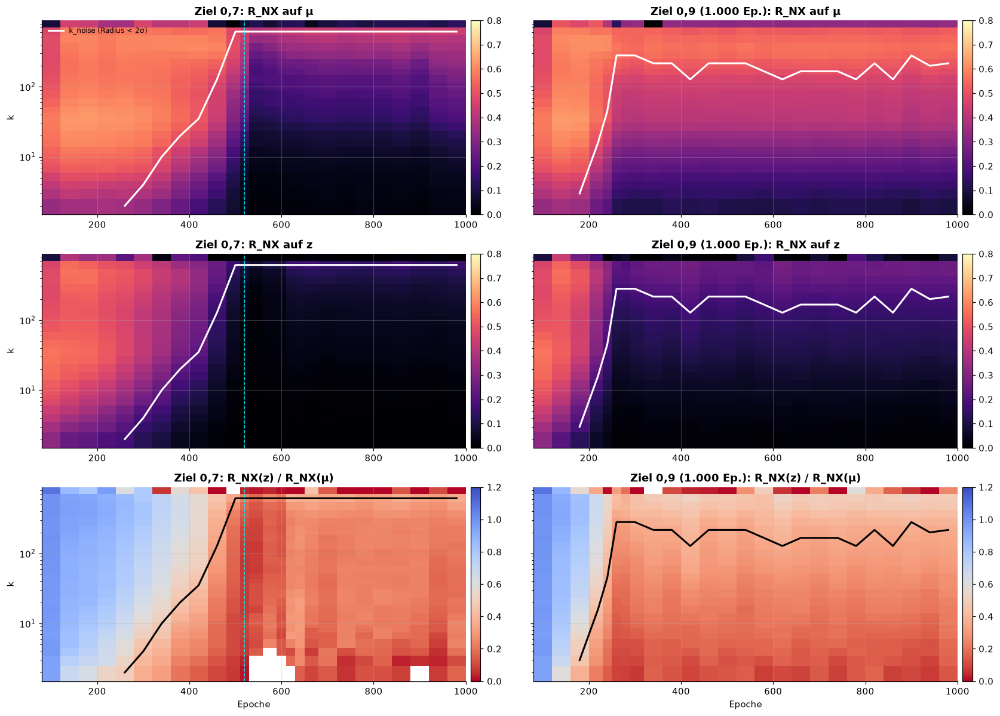

In [18]:
fig, axes = plt.subplots(3, len(SWEEP_RUNS), figsize=(8 * len(SWEEP_RUNS), 11), sharey=True)
for column, run in enumerate(SWEEP_RUNS):
    part = k_sweep[k_sweep.run.eq(run)]
    grids = {space: part[part.space.eq(space)].pivot(index="k", columns="epoch", values="r_nx") for space in ("μ", "z")}
    ratio = (grids["z"] / grids["μ"].where(grids["μ"] > .02)).clip(0, 1.2)
    line = noise_k[noise_k.run.eq(run)].set_index("epoch").k_noise.reindex(grids["μ"].columns)
    for row, (title, grid, cmap, limits) in enumerate((("R_NX auf μ", grids["μ"], "magma", (0, .8)),
                                                       ("R_NX auf z", grids["z"], "magma", (0, .8)),
                                                       ("R_NX(z) / R_NX(μ)", ratio, "coolwarm_r", (0, 1.2)))):
        ax = axes[row, column]
        mesh = ax.pcolormesh(grid.columns, grid.index, grid.to_numpy(), cmap=cmap, vmin=limits[0], vmax=limits[1], shading="nearest")
        ax.plot(line.index, line.to_numpy(), color="white" if row < 2 else "black", lw=2, label="k_noise (Radius < 2σ)")
        if run in first_collapse:
            ax.axvline(first_collapse[run], color="cyan", ls="--", lw=1)
        ax.set(yscale="log", title=f"{run}: {title}", ylabel="k" if column == 0 else None)
        fig.colorbar(mesh, ax=ax, pad=.01)
        if row == 0 and column == 0:
            ax.legend(fontsize=8, loc="upper left")
    axes[-1, column].set_xlabel("Epoche")
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "rnx_heatmap_noise.png", dpi=150); plt.show()

# Quantitativer Test: Mittleres Verhältnis z/μ für k unter und über k_noise
test = k_sweep[k_sweep.space.eq("μ")].merge(k_sweep[k_sweep.space.eq("z")], on=["run", "epoch", "k"], suffixes=("_mu", "_z"))
test = test.merge(noise_k, on=["run", "epoch"], how="left")
test = test[test.k_noise.notna() & (test.r_nx_mu > .02)]
test["lage"] = np.where(test.k <= test.k_noise, "k ≤ k_noise (im Rauschen)", "k > k_noise")
test["verhaeltnis"] = test.r_nx_z / test.r_nx_mu
display(test.groupby(["run", "lage"]).verhaeltnis.describe()[["count", "25%", "50%", "75%"]].round(3)
        .style.format(precision=3).set_caption("R_NX(z) / R_NX(μ) unter und über dem Rausch-Radius"))

### 5.3 Lokal gegen global

Skalenübergreifende und globale Maße über die Epochen, auf μ: AUC_logk (log-gewichtete R_NX-Fläche), R_NX bei 1 %, 10 % und
25 % von n, Spearman der Paardistanzen, DTM und KL (je σ = 0,1 und 1; kleiner = besser). Dazu die erste Epoche, ab der jedes Maß
20 % schlechter ist als am Ende des Warm-ups. So „battlen“ lokale und globale Struktur: Was bricht zuerst?

/tmp/ipykernel_2057715/1713239152.py:15: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(group.epoch, loss.clip(upper=100), "o-", ms=3, lw=1.3, label=label,
/tmp/ipykernel_2057715/1713239152.py:15: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(group.epoch, loss.clip(upper=100), "o-", ms=3, lw=1.3, label=label,
/tmp/ipykernel_2057715/1713239152.py:15: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(group.epoch, loss.clip(upper=100), "o-", ms=3, lw=1.3, label=label,
/tmp/ipykernel_2057715/1713239152.py:15: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt s

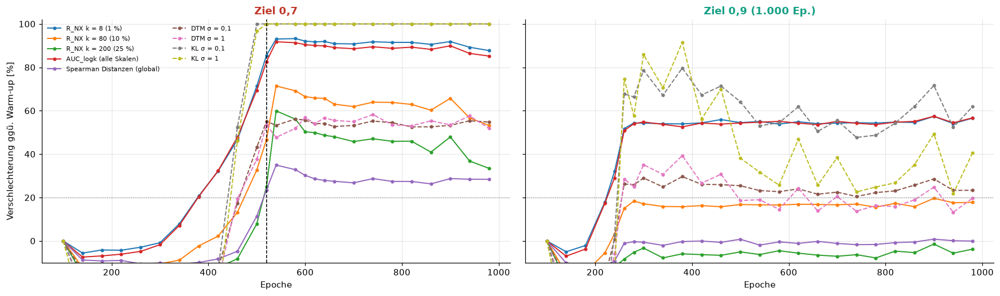

run,mass,erste_epoche_20,warmup,ende
"Ziel 0,7",R_NX k = 8 (1 %),380,0.513409,0.063119
"Ziel 0,7",AUC_logk (alle Skalen),380,0.443063,0.065653
"Ziel 0,7","KL σ = 0,1",460,0.048509,0.112714
"Ziel 0,7",KL σ = 1,460,0.000979,0.002502
"Ziel 0,7",R_NX k = 80 (10 %),500,0.519846,0.243245
"Ziel 0,7","DTM σ = 0,1",500,0.239996,0.371432
"Ziel 0,7",DTM σ = 1,500,0.032840,0.049882
"Ziel 0,7",R_NX k = 200 (25 %),520,0.485694,0.323318
"Ziel 0,7",Spearman Distanzen (global),520,0.737077,0.527936
"Ziel 0,9 (1.000 Ep.)",R_NX k = 8 (1 %),240,0.513409,0.223002


In [19]:
pick = k_sweep[k_sweep.space.eq("μ") & k_sweep.k.isin([8, 80, 200])].pivot_table(index=["run", "epoch"], columns="k", values="r_nx")
pick.columns = [f"r_nx_k{k}" for k in pick.columns]
battle = global_measures[global_measures.space.eq("μ")].merge(pick.reset_index(), on=["run", "epoch"])
BATTLE = {"r_nx_k8": ("R_NX k = 8 (1 %)", +1), "r_nx_k80": ("R_NX k = 80 (10 %)", +1), "r_nx_k200": ("R_NX k = 200 (25 %)", +1),
          "auc_logk": ("AUC_logk (alle Skalen)", +1), "spearman": ("Spearman Distanzen (global)", +1),
          "dtm_0.1": ("DTM σ = 0,1", -1), "dtm_1": ("DTM σ = 1", -1), "kl_0.1": ("KL σ = 0,1", -1), "kl_1": ("KL σ = 1", -1)}
fig, axes = plt.subplots(1, len(SWEEP_RUNS), figsize=(8 * len(SWEEP_RUNS), 4.8), sharey=True)
order_rows = []
for ax, run in zip(axes, SWEEP_RUNS):
    group = battle[battle.run.eq(run)].sort_values("epoch")
    reference = group[group.epoch.eq(REFERENCE_EPOCH)].iloc[0]
    for column, (label, direction) in BATTLE.items():
        change = (group[column] - reference[column]) / abs(reference[column])
        loss = 100 * (-change if direction > 0 else change)
        ax.plot(group.epoch, loss.clip(upper=100), "o-", ms=3, lw=1.3, label=label,
                ls="-" if direction > 0 else "--")
        hit = group[loss >= 20]
        order_rows.append(dict(run=run, mass=label, erste_epoche_20=hit.epoch.iloc[0] if len(hit) else np.nan,
                               warmup=reference[column], ende=group[column].iloc[-1]))
    if run in first_collapse:
        ax.axvline(first_collapse[run], color="black", ls="--", lw=1)
    ax.axhline(20, color="gray", ls=":", lw=.8)
    ax.set(title=run, xlabel="Epoche", ylim=(-10, 102))
    ax.title.set_color(RUN_COLORS[run])
axes[0].set_ylabel("Verschlechterung ggü. Warm-up [%]")
axes[0].legend(fontsize=7.5, ncol=2)
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "local_vs_global.png", dpi=150); plt.show()
local_global_order = pd.DataFrame(order_rows).sort_values(["run", "erste_epoche_20"], na_position="last")
local_global_order.to_csv(COLLAPSE_ROOT / "local_vs_global_order.csv", index=False)
display(local_global_order.style.format(precision=3).format({"erste_epoche_20": "{:.0f}"}, na_rep="–").hide(axis="index"))

### 5.4 Jede Metrik mit eigenem k-Sweep

Bisher lief nur R_NX über alle k. Hier bekommt jede Preservation-Metrik ihren eigenen Sweep: Trustworthiness, Continuity,
MRRE false, MRRE missing und R_NX, jeweils auf μ. Die Kurven zeigen die Metrik über k zu fünf Zeitpunkten: Ende Warm-up,
die beiden Snapshots vor dem Ereignis (Collapse bzw. Trustworthiness-Stopp), der erste danach und das Laufende.
Trustworthiness und Continuity sind nur für k < n/2 = 400 definiert. Damit lässt sich prüfen, ob Trustworthiness nur bei
k = 20 träge ist oder auf jeder Skala, und ob die Reihenfolge „lokal vor global“ für alle Metriken gilt.

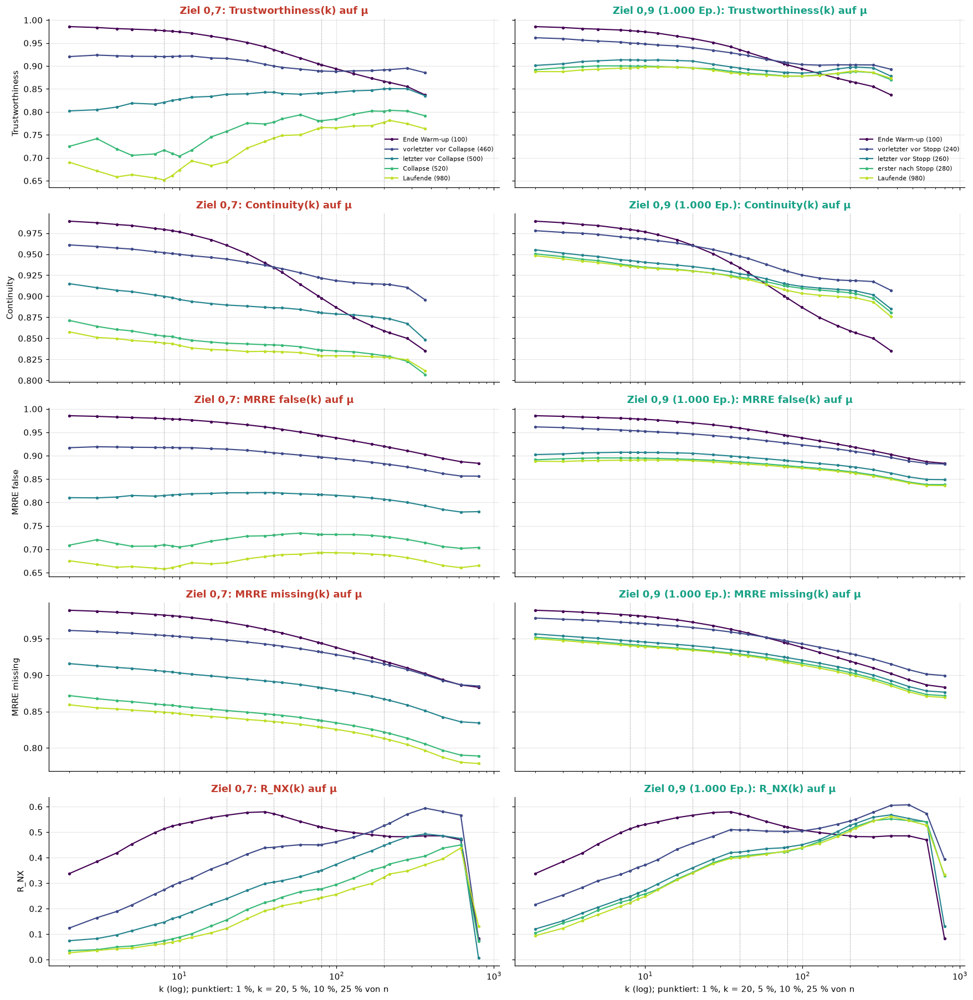

In [20]:
K_METRICS = {"trustworthiness": "Trustworthiness", "continuity": "Continuity", "mrre_false": "MRRE false",
             "mrre_missing": "MRRE missing", "r_nx": "R_NX"}


def event_moments(run):
    """Ende Warm-up, zwei Snapshots vor dem Ereignis, erster danach, Laufende (nur Epochen mit k-Sweep)."""
    available = sweep_epochs(run)
    if run in first_collapse:
        event = first_collapse[run]
        before = [e for e in available if e < event]
        moments = {"Ende Warm-up": REFERENCE_EPOCH, "vorletzter vor Collapse": before[-2],
                   "letzter vor Collapse": before[-1], "Collapse": event}
    else:
        stop = stop_snapshots(run)
        moments = {"Ende Warm-up": REFERENCE_EPOCH, "vorletzter vor Stopp": stop["before_2"],
                   "letzter vor Stopp": stop["before"], "erster nach Stopp": stop["after"]}
    moments["Laufende"] = max(available)
    return moments


fig, axes = plt.subplots(len(K_METRICS), len(SWEEP_RUNS), figsize=(8 * len(SWEEP_RUNS), 3.3 * len(K_METRICS)),
                         sharex=True, sharey="row")
for column, run in enumerate(SWEEP_RUNS):
    moments = event_moments(run)
    colors = plt.cm.viridis(np.linspace(0, .9, len(moments)))
    for row, (metric, label) in enumerate(K_METRICS.items()):
        ax = axes[row, column]
        for color, (name, epoch) in zip(colors, moments.items()):
            curve = k_sweep[(k_sweep.run == run) & (k_sweep.epoch == epoch) & (k_sweep.space == "μ")].dropna(subset=[metric])
            ax.plot(curve.k, curve[metric], "o-", ms=2.5, lw=1.4, color=color, label=f"{name} ({epoch})")
        for k in (8, 20, 40, 80, 200):
            ax.axvline(k, color="gray", ls=":", lw=.7)
        ax.set(xscale="log", ylabel=label if column == 0 else None, title=f"{run}: {label}(k) auf μ")
        ax.title.set_color(RUN_COLORS[run])
    axes[0, column].legend(fontsize=7.5, loc="lower right")
    axes[-1, column].set_xlabel("k (log); punktiert: 1 %, k = 20, 5 %, 10 %, 25 % von n")
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "k_sweep_per_metric.png", dpi=150); plt.show()

Dieselbe Information als Tabelle: Änderung jeder Metrik gegenüber dem Ende des Warm-ups beim letzten Snapshot vor dem
Ereignis, für ausgewählte k, auf μ und auf z. Negativ = schlechter (alle fünf Metriken: größer = besser).

In [21]:
K_SHOW = [5, 10, 20, 40, 80, 200]
change_rows = []
for run in SWEEP_RUNS:
    moments = event_moments(run)
    event_name = next(name for name in moments if name.startswith("letzter vor"))
    for space in ("μ", "z"):
        part = k_sweep[(k_sweep.run == run) & (k_sweep.space == space) & k_sweep.k.isin(K_SHOW)].set_index(["epoch", "k"])
        for metric, label in K_METRICS.items():
            start, event = part.loc[moments["Ende Warm-up"], metric], part.loc[moments[event_name], metric]
            change_rows.append({"Lauf": f"{run} ({event_name}, {moments[event_name]})", "Raum": space, "Metrik": label,
                                **{f"k = {k}": 100 * (event[k] - start[k]) / abs(start[k]) for k in K_SHOW}})
k_change = pd.DataFrame(change_rows).set_index(["Lauf", "Raum", "Metrik"])
k_change.to_csv(COLLAPSE_ROOT / "k_sweep_per_metric_change.csv")
display(k_change.style.format("{:+.0f} %", na_rep="–").background_gradient(cmap="RdBu", vmin=-60, vmax=60, axis=None)
        .set_caption("Änderung gegenüber Ende Warm-up [%], letzter Snapshot vor Collapse bzw. Stopp"))

## 6. Kurz vor dem Trustworthiness-Stopp

Wie sieht die Repräsentation aus, wenn der Controller aufhört, β zu erhöhen? Im 1.000-Epochen-Lauf liegt die Messung bei
Epoche 260 (Trustworthiness 0,910) erstmals im Zielband; ab Epoche 261 steht der Controller im Zustand „hold“. Die letzte
β-Erhöhung kam nach der Messung bei Epoche 255 (β/d = 1,5·10⁻³ ab Epoche 256). Der Snapshot bei Epoche 260 ist damit
genau der Zustand bei der Stopp-Entscheidung. (Im Controller-Log steht in jeder Zeile der Zustand, mit dem die Epoche
trainiert wurde; die Entscheidung aus einer Messung erscheint erst in der Folgezeile.) Danach fällt Trustworthiness noch kurz weiter, weil das Modell der letzten Erhöhung nachzieht, und der
Controller nimmt β nach den Messungen bei Epoche 285 und 320 (T = 0,889, knapp unter dem Band) leicht zurück.

Verglichen werden vier Snapshots: Ende Warm-up (Epoche 100), der vorletzte Snapshot vor dem Stopp, der letzte Snapshot vor
dem Stopp und der erste Snapshot nach dem Stopp, dazu das Laufende. Alle Werte auf dem festen Controller-Subset
(800 Validierungspatienten) bzw. für die AUC auf z (Train → Validation). R_NX aus dem k-Sweep in Abschnitt 5,
mit k = 10, 40, 80 (10 % von n) und 200 (25 % von n).

In [22]:
STOP_RUN = "Ziel 0,9 (1.000 Ep.)"
stop_moments = stop_snapshots(STOP_RUN)
print("Stopp (erste Messung im Zustand 'hold'):", stop_moments["stop_epoch"])
moments = {"Ende Warm-up": REFERENCE_EPOCH, "vorletzter vor Stopp": stop_moments["before_2"],
           "letzter vor Stopp": stop_moments["before"], "erster nach Stopp": stop_moments["after"],
           "Laufende": max(sweep_epochs(STOP_RUN))}  # letzter Snapshot mit k-Sweep

group = snapshots[snapshots.run.eq(STOP_RUN)].set_index("epoch")
dims = dimensions[dimensions.run.eq(STOP_RUN)]
topo = topology[topology.run.eq(STOP_RUN)].set_index("epoch")
ks = k_sweep[k_sweep.run.eq(STOP_RUN)]
auc8 = cohort_auc[cohort_auc.run.eq(STOP_RUN) & cohort_auc.cohort.eq("8 Krebsarten")].set_index("epoch").auc
rows = {}
for name, epoch in moments.items():
    snap, dim = group.loc[epoch], dims[dims.epoch.eq(epoch)]
    row = {"Epoche": epoch, "β/d": snap.beta_over_d, "Rate [Nats]": snap.rate,
           "kollabierte Dimensionen": snap.collapsed_dimensions,
           "kleinste KL einer Dimension": dim.kl_mean.min(),
           "größter Anteil μ = 0 in einer Dimension": dim.zero_fraction.max(),
           "Patienten mit μ = 0 überall": snap.zero_patients,
           "Trustworthiness (k = 20)": snap.trustworthiness, "MRRE false (k = 20)": snap.mrre_false,
           "LCMC (k = 20)": snap.lcmc}
    for space in ("μ", "z"):
        for k in (10, 40, 80, 200):
            value = ks[(ks.epoch == epoch) & (ks.space == space) & (ks.k == k)].r_nx
            row[f"R_NX k = {k} auf {space}"] = value.iloc[0] if len(value) else np.nan
    row.update({"Krebs-AUC (33)": snap.auc_cancer, "Krebs-AUC (8)": auc8.get(epoch, np.nan),
                "Geschlechts-AUC": snap.auc_sex, "Rekonstruktionsfehler": snap.recon_valid,
                "Komponenten bei 2σ (t = 1) [%]": 100 * topo.loc[epoch, "fs_h0_components_t1"] / N_REFERENCE})
    rows[f"{name} ({epoch})"] = row
stop_table = pd.DataFrame(rows)
reference = stop_table.iloc[:, 0]
change = 100 * stop_table.iloc[:, 1:].sub(reference, axis=0).div(reference.abs().replace(0, np.nan), axis=0)
stop_table.to_csv(COLLAPSE_ROOT / "state_before_stop.csv")
display(stop_table.style.format(precision=3).format(subset=pd.IndexSlice[["β/d", "Rekonstruktionsfehler"], :], formatter="{:.2e}")
        .format(subset=pd.IndexSlice[["Epoche", "kollabierte Dimensionen"], :], formatter="{:.0f}")
        .set_caption(f"{STOP_RUN}: Zustand um den Trustworthiness-Stopp"))
display(change.drop(index=["Epoche", "kollabierte Dimensionen"]).round(0).style.format("{:+.0f} %", na_rep="–")
        .background_gradient(cmap="RdBu", vmin=-60, vmax=60, axis=None)
        .set_caption("Änderung gegenüber Ende Warm-up [%] (μ = 0-Anteile und Rate: relative Änderung)"))

Stopp (erste Messung im Zustand 'hold'): 261


,Ende Warm-up (100),vorletzter vor Stopp (240),letzter vor Stopp (260),erster nach Stopp (280),Laufende (980)
Epoche,100,240,260,280,980
β/d,0.00e+00,6.20e-04,1.51e-03,1.51e-03,1.21e-03
Rate [Nats],2093.645,5.989,2.397,2.374,2.905
kollabierte Dimensionen,0,0,0,0,0
kleinste KL einer Dimension,1.047,0.428,0.185,0.199,0.224
größter Anteil μ = 0 in einer Dimension,0.365,0.738,0.857,0.884,0.920
Patienten mit μ = 0 überall,0.000,0.009,0.083,0.059,0.071
Trustworthiness (k = 20),0.960,0.940,0.910,0.896,0.896
MRRE false (k = 20),0.970,0.947,0.905,0.892,0.889
LCMC (k = 20),0.552,0.445,0.351,0.334,0.331


,vorletzter vor Stopp (240),letzter vor Stopp (260),erster nach Stopp (280),Laufende (980)
β/d,–,–,–,–
Rate [Nats],-100 %,-100 %,-100 %,-100 %
kleinste KL einer Dimension,-59 %,-82 %,-81 %,-79 %
größter Anteil μ = 0 in einer Dimension,+102 %,+135 %,+142 %,+152 %
Patienten mit μ = 0 überall,–,–,–,–
Trustworthiness (k = 20),-2 %,-5 %,-7 %,-7 %
MRRE false (k = 20),-2 %,-7 %,-8 %,-8 %
LCMC (k = 20),-19 %,-36 %,-40 %,-40 %
R_NX k = 10 auf μ,-30 %,-49 %,-51 %,-53 %
R_NX k = 40 auf μ,-11 %,-26 %,-29 %,-30 %


### 6.1 Verlauf um den Stopp

Ausschnitt Epoche 100–400 des 1.000-Epochen-Laufs. Oben das Steuersignal (Trustworthiness alle 5 Epochen), in der Mitte β/d
(eigene Achse, logarithmisch).
Unten die übrigen Größen, jeweils relativ zum Ende des Warm-ups (100 % = unverändert). Die senkrechte Linie markiert den
Stopp. Abzulesen ist, welche Größen beim Stopp schon wie weit gefallen sind und welche noch nachziehen.

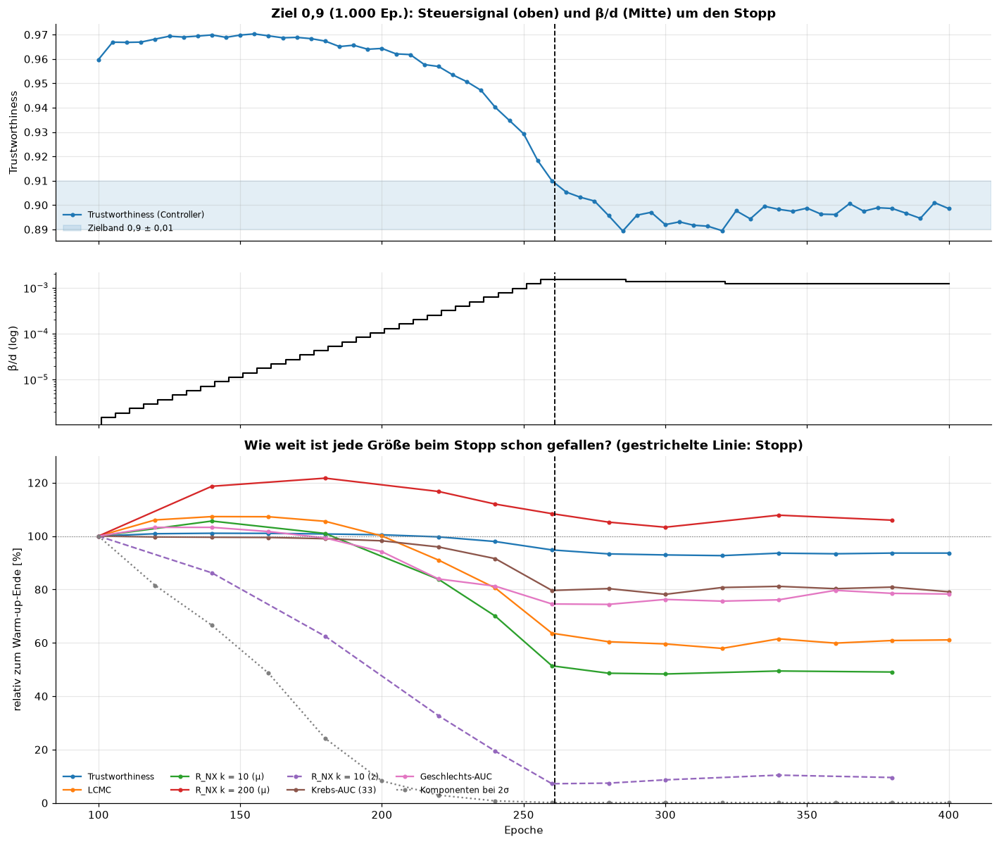

In [23]:
controller = pd.read_csv(run_folder(STOP_RUN) / "controller_log.csv")
window = controller[(controller.epoch >= REFERENCE_EPOCH) & (controller.epoch <= 400)]
fig, (top, middle, bottom) = plt.subplots(3, 1, figsize=(13, 11), sharex=True, gridspec_kw=dict(height_ratios=[1, .7, 1.6]))
measured = window.dropna(subset=["metric_value"])
top.plot(measured.epoch, measured.metric_value, "o-", ms=3, color="#1f77b4", label="Trustworthiness (Controller)")
top.axhspan(.89, .91, color="#1f77b4", alpha=.12, label="Zielband 0,9 ± 0,01")
top.set(ylabel="Trustworthiness", title=f"{STOP_RUN}: Steuersignal (oben) und β/d (Mitte) um den Stopp")
top.legend(fontsize=8, loc="lower left")
middle.step(window.epoch, window.beta_over_d, where="post", color="black", lw=1.4)
middle.set(yscale="log", ylabel="β/d (log)")

trace = group[(group.index >= REFERENCE_EPOCH) & (group.index <= 400)]
r_nx = ks[ks.space.eq("μ")].pivot(index="epoch", columns="k", values="r_nx")
r_nx_z = ks[ks.space.eq("z")].pivot(index="epoch", columns="k", values="r_nx")
series = {"Trustworthiness": trace.trustworthiness, "LCMC": trace.lcmc,
          "R_NX k = 10 (μ)": r_nx[10], "R_NX k = 200 (μ)": r_nx[200], "R_NX k = 10 (z)": r_nx_z[10],
          "Krebs-AUC (33)": trace.auc_cancer, "Geschlechts-AUC": trace.auc_sex,
          "Komponenten bei 2σ": topo.fs_h0_components_t1}
styles = {"R_NX k = 10 (z)": "--", "Komponenten bei 2σ": ":"}
for label, values in series.items():
    values = values[(values.index >= REFERENCE_EPOCH) & (values.index <= 400)].dropna()
    bottom.plot(values.index, 100 * values / values.loc[REFERENCE_EPOCH], styles.get(label, "-"), marker="o", ms=3, lw=1.5, label=label)
for ax in (top, middle, bottom):
    ax.axvline(stop_moments["stop_epoch"], color="black", ls="--", lw=1.2)
bottom.axhline(100, color="gray", ls=":", lw=.8)
bottom.set(xlabel="Epoche", ylabel="relativ zum Warm-up-Ende [%]", ylim=(0, 130),
           title="Wie weit ist jede Größe beim Stopp schon gefallen? (gestrichelte Linie: Stopp)")
bottom.legend(fontsize=8, ncol=4, loc="lower left")
fig.tight_layout(); fig.savefig(COLLAPSE_ROOT / "around_stop.png", dpi=150); plt.show()

## 7. Einordnung

**Steuerung über 1.000 Epochen.** Der Controller erreicht das Zielband erstmals bei Epoche 260 und hält β/d danach
(nach zwei kleinen Korrekturen) konstant bei 1,2·10⁻³; 99 % der Messungen danach liegen im Band, die größte Abweichung
ist 0,011. Zum Vergleich der Lauf mit Sollwert 0,7: erst ab Epoche 620 im Band, danach nur 40 % der Messungen im Band
und 45 β-Änderungen, weil der Sollwert hinter dem Collapse liegt. Von Epoche 300 bis 1.000 bleiben Trustworthiness (0,89–0,90), Rate (≈ 3 Nats), Krebs-AUC (0,77–0,83) und
Geschlechts-AUC (0,62–0,69) stabil; keine Dimension kollabiert. Bis Epoche 500 ist der Lauf mit dem 500-Epochen-Lauf
deckungsgleich (gleicher Seed, deterministisches Training); die zusätzlichen 500 Epochen zeigen, dass der gehaltene
Zustand kein Übergang, sondern ein Gleichgewicht ist.

**Der Preis des Sollwerts 0,9.** Gegenüber dem Warm-up-Ende ist die Krebs-AUC um ≈ 18 % gefallen (0,99 → 0,81) und die
Geschlechts-AUC um ≈ 20 % (0,83 → 0,66), obwohl Trustworthiness nur um 7 % und MRRE false um 8 % sinken. LCMC verliert
dagegen 40 % (0,55 → 0,33). Die Reihenfolge der Zerstörung ist dieselbe wie im kollabierenden Lauf:
Rekonstruktion → Geschlecht → LCMC/Cohesiveness/Krebsart → Trustworthiness/MRRE false → Dimensionen; das Annealing hält an,
bevor die Dimensionen folgen. Trustworthiness und MRRE false sind als Sollwert also spät: Wenn sie 0,9 erreichen, ist ein
großer Teil der Downstream-Information schon weg.

**Kündigt eine Metrik den AUC-Verlust an? (Abschnitt 2.6)** Im letzten Snapshot vor dem ersten 5 %-Abfall der Krebs-AUC
(alle 33) stehen Trustworthiness und MRRE false noch bei 99 % ihres Warm-up-Werts, LCMC nur noch bei 89–91 %. LCMC ist damit
die einzige der drei Metriken, die den Verlust vorher sichtbar macht. Für die acht Präsentations-Krebsarten kündigt keine
Metrik den Abfall an (alle ≈ 100 %).

**Nahe an der Kante.** Keine Dimension ist kollabiert, aber in den Dimensionen 0, 5 und 7 liegt μ für 88–92 % der Patienten
exakt bei 0 (ε-δ-Collapse verlangt 99 %). Insgesamt sind ≈ 80 % aller μ-Einträge 0, und 2–9 % der Patienten liegen in allen
Dimensionen bei μ = 0. Der stabile Zustand ist also ein stark sparser Code knapp vor dem Dimensions-Collapse.
Dimension 0 trägt weiterhin die meiste Geschlechtsinformation (η² ≈ 0,44, aber auch Krebsart η² ≈ 0,82); sie ist auch im
kollabierenden Lauf zuerst verschwunden.

**Topologie.** Bei fester Rauschskala (t = 1, 2σ) sind ab Epoche 260 alle Patienten zu einer Komponente verbunden (Epoche 240: 6):
In z liegt jeder Patient innerhalb einer Kette von Nachbarn, die jeweils weniger als 2σ Rauschen voneinander entfernt sind.
Die durchmesser-normierten X↔μ-Abstände ändern sich dagegen kaum; sie messen die relative Form, nicht die Kontraktion.
H1-Persistenz-Entropie von μ sinkt von 5,5 (Warm-up) auf 3,9–4,3 (ab Epoche 300), unter die von X (4,55).

**Skalen (Abschnitt 5).** Der k-Sweep zeigt, dass die Struktur von klein nach groß bricht. Im kollabierenden Lauf
erreicht R_NX bei k = 8 (1 % von n) und die log-gewichtete Fläche AUC_logk 20 % Verlust ab Epoche 380, R_NX bei k = 80 ab
500, R_NX bei k = 200 und die globale Spearman-Korrelation der Distanzen erst mit dem Collapse (520). Im 1.000-Epochen-Lauf
verliert R_NX bis zum Laufende bei k = 8–10 etwa 55 %, bei k = 20 / 40 / 80 etwa 40 / 30 / 18 %, bei k = 200 nichts; die globale Spearman-Korrelation
bleibt unverändert (0,74). Der Sollwert 0,9 opfert also die lokale Struktur und erhält die globale Ordnung. Trustworthiness
bei k = 20 sinkt dabei nur um 7 %, R_NX bei k = 20 um ≈ 40 %: Trustworthiness bestraft Fehler nach Rangabstand und reagiert
deshalb schwächer als die direkte Nachbarschaftsüberlappung. DTM und KL (ZADU) schwanken stark und eignen sich hier kaum.

**Rausch-Hypothese.** Gemessen in Rauscheinheiten liegen im 1.000-Epochen-Lauf ab Epoche 260 die nächsten ≈ 130–280
Patienten innerhalb von 2σ (k_noise); im kollabierenden Lauf wächst k_noise mit β von 2 (Epoche 260) bis 615 (ab Epoche 500).
Für k ≤ k_noise erhält z im Median nur 22–23 % der Nachbarschaftsstruktur von μ, für k > k_noise 43–61 %. Die Hypothese
bestätigt sich damit in der Richtung: Nachbarschaften innerhalb des Rauschradius zerfallen in z. Die Grenze ist aber nicht
scharf, auch oberhalb von k_noise verliert z einen Teil der Struktur. Auf μ selbst greift der Mechanismus nicht, weil μ kein
Rauschen enthält; dort bricht die lokale Struktur durch die Kontraktion und die Patienten bei μ = 0.

**Collapse-Schwelle (Abschnitt 2.4).** Im kollabierenden Lauf liegt der Collapse zwischen Trustworthiness 0,84 und 0,77,
MRRE false 0,82 und 0,72 sowie LCMC 0,23 und 0,15. Im Sweep (Median über 24 Trajektorien, alle d) liegen die Übergänge
höher (T 0,93 → 0,87); die Schwelle hängt stark von d ab. Der Sweep lief allerdings auf einem anderen Datensatz
(`OntixTutorialData`, 3.529 Patienten, 90 Epochen) als die Annealing-Läufe (`TCGAPanCancerAutoencodix`, 10.013 Patienten);
der Unterschied der Schwellen ist deshalb nicht allein dem Trainingsweg zuzuschreiben.

**Jede Metrik mit eigenem k-Sweep (Abschnitt 5.4).** Alle fünf Metriken verlieren auf μ bei kleinem k mehr als bei großem;
die Reihenfolge „lokal vor global“ ist also keine Eigenheit von R_NX. Unterschiedlich ist die Stärke: Beim Stopp (Epoche 260)
verliert Trustworthiness bei k = 5 / 20 / 200 nur 7 / 5 / −3 %, Continuity 4 / 3 / −6 %, MRRE false 8 / 7 / 5 %, R_NX dagegen
55 / 36 / −8 % (negativ = Verbesserung). Vor dem Collapse (Ziel 0,7, Epoche 500) dasselbe Bild auf höherem Niveau:
Trustworthiness −16 % bei k = 5, R_NX −75 %. Trustworthiness ist also auf keiner Skala empfindlich, nicht nur bei k = 20.
Auf z verlieren alle Metriken auf allen Skalen stark (Trustworthiness ≈ −30 %, R_NX −68 bis −95 %). MRRE ist am flachsten
über k, weil es Rangfehler bis k aufsummiert und so kleine und große Nachbarschaften mischt.

**Zustand beim Trustworthiness-Stopp (Abschnitt 6).** Die Messung bei Epoche 260 liegt im Zielband, ab Epoche 261 hält der
Controller β. Snapshot Epoche 260, relativ zum Ende des Warm-ups:

| Größe | Warm-up → vor Stopp | Änderung |
|---|---|---|
| Trustworthiness / MRRE false (k = 20) | 0,96 / 0,97 → 0,91 / 0,91 | −5 % / −7 % |
| LCMC (k = 20) | 0,55 → 0,35 | −36 % |
| R_NX auf μ, k = 10 / 40 / 80 / 200 | 0,53 / 0,57 / 0,52 / 0,49 → 0,27 / 0,42 / 0,44 / 0,53 | −49 % / −26 % / −15 % / +8 % |
| R_NX auf z, k = 10 / 200 | 0,52 / 0,48 → 0,04 / 0,15 | −93 % / −68 % |
| Krebs-AUC (33 / 8 Klassen) | 0,99 / 0,98 → 0,79 / 0,78 | −20 % / −21 % |
| Geschlechts-AUC | 0,83 → 0,62 | −25 % |
| Rate | 2.094 → 2,4 Nats | – |
| kollabierte Dimensionen | 0 → 0 | – |
| kleinste KL einer Dimension | 1,05 → 0,18 | – |
| größter Anteil μ = 0 in einer Dimension | 36 % → 86 % | – |
| Patienten mit μ = 0 überall | 0 % → 8 % | – |
| unterscheidbare Komponenten bei 2σ | 99 % → 0,1 % (eine Komponente) | – |

Beim Stopp ist also der größte Teil des Schadens schon passiert: Trustworthiness hat 5 % verloren, die lokale
Nachbarschaft (LCMC, R_NX bei kleinem k) ein Drittel bis die Hälfte, die Downstream-AUC ein Fünftel bis ein Viertel, und in z
sind die Patienten ab Epoche 260 nicht mehr durch mehr als 2σ Rauschen getrennt (Epoche 240: noch 6 Komponenten). Erhalten bleibt die grobe Struktur
(R_NX ab k ≈ 200 unverändert). Dazu kommt ein Nachlauf: Nach der letzten Erhöhung fällt Trustworthiness noch bis 0,889,
LCMC und R_NX bei k = 10 verlieren weitere 2–3 Prozentpunkte, bevor der Controller β nach den Messungen bei Epoche 285 und 320 (T = 0,889) leicht zurücknimmt;
die AUC erholt sich danach geringfügig (Krebs 0,79 → 0,81 am Ende).

**Fazit.** Der Trustworthiness-Controller hält, was er verspricht: Er stoppt vor jedem Dimensions-Collapse und hält den
Sollwert über 700 Epochen stabil. Als Frühwarnung ist Trustworthiness (k = 20) aber zu träge: Beim Stopp sind lokale
Struktur und Label-Information schon deutlich reduziert, nur die grobe Struktur ist erhalten. Ein empfindlicheres
Stoppsignal wäre LCMC bzw. R_NX bei kleinem k, oder ein Maximin aus lokalem und globalem Maß mit einem Wächter auf die
kleinste KL je Dimension.